In [1]:
from google.colab import drive
from pathlib import Path
import json

# Mount Google Drive before defining project paths
drive.mount("/content/drive")

PROJECT_ROOT = Path("/content/drive/MyDrive/Football_CV_Project")

assert PROJECT_ROOT.exists(), "Project folder not found!"

DATA_ROOT = PROJECT_ROOT / "data/raw/soccernet"
MODELS_DIR = PROJECT_ROOT / "models"

# New output directory — does not overwrite Notebook 3
OUTPUT_DIR = PROJECT_ROOT / "outputs/calibration/v2.0"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

sequences = ["SNMOT-060", "SNMOT-066", "SNMOT-069"]

print("=" * 55)
print("AUTOMATIC PITCH CALIBRATION V2 — PROJECT CHECK")
print("=" * 55)

for sequence in sequences:
    frame_dir = DATA_ROOT / sequence / "img1"
    frames = sorted(frame_dir.glob("*.jpg"))

    print(f"{sequence}: {len(frames)} frames")

    assert len(frames) > 0, f"No frames found for {sequence}"

model_path = MODELS_DIR / "football-pitch-detection.pt"

print("\nExisting pitch model:", model_path.exists())
print("Output directory:", OUTPUT_DIR)
print("\nProject initialization successful.")

Mounted at /content/drive
AUTOMATIC PITCH CALIBRATION V2 — PROJECT CHECK
SNMOT-060: 750 frames
SNMOT-066: 750 frames
SNMOT-069: 750 frames

Existing pitch model: True
Output directory: /content/drive/MyDrive/Football_CV_Project/outputs/calibration/v2.0

Project initialization successful.


In [2]:
import json
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/Football_CV_Project")

metadata_files = [
    ROOT / "outputs/calibration/v1.0/SNMOT-066/metadata.json",
    ROOT / "docs/results/SNMOT066_frame400_calibration.json",
    ROOT / "docs/results/SNMOT066_hybrid_calibration_metadata.json",
]

print("EXISTING CALIBRATION METADATA")
print("=" * 65)

for path in metadata_files:
    print(f"\nFILE: {path.relative_to(ROOT)}")

    if not path.exists():
        print("Not found")
        continue

    with open(path, "r") as f:
        data = json.load(f)

    print(json.dumps(data, indent=2)[:12000])

print("\nMetadata inspection completed.")

EXISTING CALIBRATION METADATA

FILE: outputs/calibration/v1.0/SNMOT-066/metadata.json
{
  "version": "v1.0",
  "sequence": "SNMOT-066",
  "created_utc": "2026-10-12T06:42:10.593196+00:00",
  "pitch_length_m": 120.0,
  "pitch_width_m": 70.0,
  "coordinate_system": "reference_pitch",
  "matrix_direction": "image_to_pitch",
  "frame_numbering": "one_based",
  "method": "keypoints + RANSAC + camera motion + recalibration",
  "homography_count": 101,
  "calibrated_frames": [
    350,
    351,
    352,
    353,
    354,
    355,
    356,
    357,
    358,
    359,
    360,
    361,
    362,
    363,
    364,
    365,
    366,
    367,
    368,
    369,
    370,
    371,
    372,
    373,
    374,
    375,
    376,
    377,
    378,
    379,
    380,
    381,
    382,
    383,
    384,
    385,
    386,
    387,
    388,
    389,
    390,
    391,
    392,
    393,
    394,
    395,
    396,
    397,
    398,
    399,
    400,
    401,
    402,
    403,
    404,
    405,
    406,
    407,
   

In [3]:
from pathlib import Path
import re

ROOT = Path("/content/drive/MyDrive/Football_CV_Project")

# Search only lightweight source/configuration files
extensions = {".py", ".json", ".yaml", ".yml", ".txt", ".md"}

search_dirs = [
    ROOT / "models",
    ROOT / "docs",
    ROOT / "scripts",
    ROOT / "src",
    ROOT / "configs",
]

keywords = [
    "keypoint",
    "landmark",
    "pitch_vertices",
    "pitch_coordinates",
    "vertex",
    "homography",
    "soccerpitch",
]

print("SEARCHING FOR EXISTING PITCH-COORDINATE DEFINITIONS")
print("=" * 65)

matches = []

for folder in search_dirs:

    if not folder.exists():
        continue

    for path in folder.rglob("*"):

        if not path.is_file():
            continue

        if path.suffix.lower() not in extensions:
            continue

        # Avoid reading large files
        if path.stat().st_size > 2_000_000:
            continue

        try:
            content = path.read_text(
                encoding="utf-8",
                errors="ignore"
            )
        except Exception:
            continue

        lines = content.splitlines()

        relevant = [
            (i + 1, line.strip())
            for i, line in enumerate(lines)
            if any(
                keyword in line.lower()
                for keyword in keywords
            )
        ]

        if relevant:
            matches.append((path, relevant))

for path, relevant in matches[:20]:

    print(f"\nFILE: {path.relative_to(ROOT)}")

    for line_number, line in relevant[:12]:
        print(f"  Line {line_number}: {line[:180]}")

print("\nFiles containing relevant definitions:", len(matches))

if not matches:
    print(
        "\nNo definitions found in project source/config files."
    )
    print(
        "The mapping may exist only inside an earlier Colab notebook."
    )

print("\nInspection completed. No files were modified.")

SEARCHING FOR EXISTING PITCH-COORDINATE DEFINITIONS

FILE: docs/results/SNMOT066_frame400_calibration.json
  Line 4: "method": "YOLO pitch keypoints + RANSAC homography",
  Line 5: "landmarks": 13,
  Line 12: "Only 5 of 13 landmarks are RANSAC inliers",
  Line 14: "Homography applies to Frame 400, not the entire moving-camera sequence",

FILE: docs/results/SNMOT066_hybrid_calibration_metadata.json
  Line 5: "method": "Pitch keypoints + periodic recalibration + optical flow",

Files containing relevant definitions: 2

Inspection completed. No files were modified.


In [4]:
from pathlib import Path
import json
import re

ROOT = Path("/content/drive/MyDrive/Football_CV_Project")

keywords = [
    "vertices",
    "vertex",
    "keypoint",
    "pitch_coordinates",
    "pitch_length",
    "pitch_width",
    "homography",
    "SoccerPitchConfiguration",
    "CONFIG",
]

# Search notebooks throughout the project
notebooks = sorted(ROOT.rglob("*.ipynb"))

print("NOTEBOOK KEYPOINT MAPPING SEARCH")
print("=" * 65)
print("Notebooks found:", len(notebooks))

for notebook in notebooks:

    try:
        with open(notebook, "r", encoding="utf-8") as f:
            data = json.load(f)
    except Exception as e:
        print("Could not read:", notebook.name, e)
        continue

    matches = []

    for cell_number, cell in enumerate(
        data.get("cells", []), start=1
    ):

        if cell.get("cell_type") != "code":
            continue

        source = "".join(cell.get("source", []))

        lines = source.splitlines()

        relevant_lines = [
            (i + 1, line.strip())
            for i, line in enumerate(lines)
            if any(k.lower() in line.lower() for k in keywords)
        ]

        if relevant_lines:
            matches.append((cell_number, relevant_lines))

    if matches:

        print(f"\nNOTEBOOK: {notebook.relative_to(ROOT)}")
        print("Matching cells:", len(matches))

        for cell_number, lines in matches[:12]:

            print(f"\n  Cell {cell_number}")

            for line_number, line in lines[:8]:
                print(
                    f"    Line {line_number}: {line[:160]}"
                )

print("\nSearch completed.")

NOTEBOOK KEYPOINT MAPPING SEARCH
Notebooks found: 5

NOTEBOOK: notebooks/02_SoccerNet_Data_Preparation.ipynb
Matching cells: 2

  Cell 19
    Line 1: import configparser
    Line 11: config = configparser.ConfigParser()
    Line 12: config.read(ini_path)
    Line 16: for key, value in config["Sequence"].items():

  Cell 20
    Line 13: config = configparser.ConfigParser()
    Line 14: config.read(ini_path)
    Line 16: info = config["Sequence"]

NOTEBOOK: notebooks/03_Pitch_Calibration_and_Homography.ipynb
Matching cells: 62

  Cell 5
    Line 4: PITCH_LENGTH = 105
    Line 5: PITCH_WIDTH = 68
    Line 13: PITCH_LENGTH,
    Line 14: PITCH_WIDTH,
    Line 23: [PITCH_LENGTH / 2, PITCH_LENGTH / 2],
    Line 24: [0, PITCH_WIDTH],
    Line 32: (PITCH_LENGTH / 2, PITCH_WIDTH / 2),
    Line 42: PITCH_LENGTH / 2,

  Cell 10
    Line 38: "SNMOT-060 — Frame 600: Homography Calibration"

  Cell 29
    Line 1: from sports.configs.soccer import SoccerPitchConfiguration
    Line 4: CONFIG = SoccerPi

In [5]:
import sys
import subprocess

print("Python version:", sys.version)

# Install Roboflow Sports from its GitHub repository
subprocess.check_call([
    sys.executable,
    "-m",
    "pip",
    "install",
    "-q",
    "git+https://github.com/roboflow/sports.git"
])

# Verify the installation
from sports.configs.soccer import SoccerPitchConfiguration

CONFIG = SoccerPitchConfiguration()

print("\nSPORTS LIBRARY INSTALLED SUCCESSFULLY")
print("=" * 55)
print("Pitch length:", CONFIG.length)
print("Pitch width:", CONFIG.width)
print("Number of reference vertices:", len(CONFIG.vertices))
print("First five vertices:", CONFIG.vertices[:5])

Python version: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]

SPORTS LIBRARY INSTALLED SUCCESSFULLY
Pitch length: 12000
Pitch width: 7000
Number of reference vertices: 32
First five vertices: [(0, 0), (0, 1450.0), (0, 2584.0), (0, 4416.0), (0, 5550.0)]


REFERENCE PITCH LANDMARKS
Keypoint 00: X =    0.00 m, Y =    0.00 m
Keypoint 01: X =    0.00 m, Y =   14.50 m
Keypoint 02: X =    0.00 m, Y =   25.84 m
Keypoint 03: X =    0.00 m, Y =   44.16 m
Keypoint 04: X =    0.00 m, Y =   55.50 m
Keypoint 05: X =    0.00 m, Y =   70.00 m
Keypoint 06: X =    5.50 m, Y =   25.84 m
Keypoint 07: X =    5.50 m, Y =   44.16 m
Keypoint 08: X =   11.00 m, Y =   35.00 m
Keypoint 09: X =   20.15 m, Y =   14.50 m
Keypoint 10: X =   20.15 m, Y =   25.84 m
Keypoint 11: X =   20.15 m, Y =   44.16 m
Keypoint 12: X =   20.15 m, Y =   55.50 m
Keypoint 13: X =   60.00 m, Y =    0.00 m
Keypoint 14: X =   60.00 m, Y =   25.85 m
Keypoint 15: X =   60.00 m, Y =   44.15 m
Keypoint 16: X =   60.00 m, Y =   70.00 m
Keypoint 17: X =   99.85 m, Y =   14.50 m
Keypoint 18: X =   99.85 m, Y =   25.84 m
Keypoint 19: X =   99.85 m, Y =   44.16 m
Keypoint 20: X =   99.85 m, Y =   55.50 m
Keypoint 21: X =  109.00 m, Y =   35.00 m
Keypoint 22: X =  114.50 m, Y =   25.84 m
Keypoint

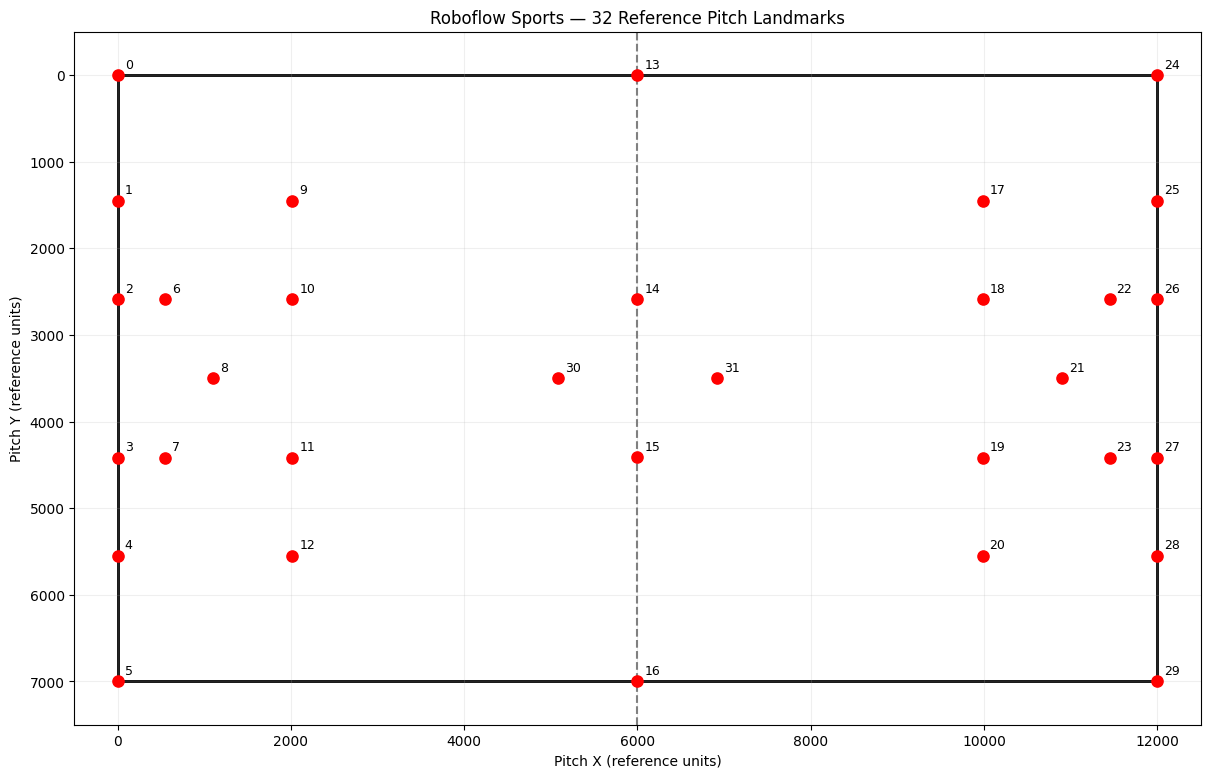


Reference pitch visualization completed.


In [6]:
import numpy as np
import matplotlib.pyplot as plt

vertices = np.asarray(CONFIG.vertices, dtype=np.float64)

assert vertices.shape == (32, 2), (
    f"Unexpected vertex shape: {vertices.shape}"
)

print("REFERENCE PITCH LANDMARKS")
print("=" * 60)

for i, (x, y) in enumerate(vertices):
    print(
        f"Keypoint {i:02d}: "
        f"X = {x / 100:7.2f} m, "
        f"Y = {y / 100:7.2f} m"
    )

fig, ax = plt.subplots(figsize=(16, 9))

# Pitch boundary
ax.add_patch(
    plt.Rectangle(
        (0, 0),
        CONFIG.length,
        CONFIG.width,
        fill=False,
        edgecolor="black",
        linewidth=2
    )
)

# Halfway line
ax.axvline(
    CONFIG.length / 2,
    color="gray",
    linestyle="--",
    linewidth=1.5
)

# Reference landmarks
ax.scatter(
    vertices[:, 0],
    vertices[:, 1],
    color="red",
    s=65,
    zorder=3
)

for i, (x, y) in enumerate(vertices):
    ax.annotate(
        str(i),
        (x, y),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=9
    )

ax.set_xlim(-500, CONFIG.length + 500)
ax.set_ylim(CONFIG.width + 500, -500)
ax.set_aspect("equal")

ax.set_title(
    "Roboflow Sports — 32 Reference Pitch Landmarks"
)

ax.set_xlabel("Pitch X (reference units)")
ax.set_ylabel("Pitch Y (reference units)")

ax.grid(alpha=0.2)

plt.show()

print("\nReference pitch visualization completed.")

In [7]:
import sys
import subprocess

try:
    from ultralytics import YOLO
    print("Ultralytics is already installed.")

except ImportError:
    print("Installing Ultralytics...")

    subprocess.check_call([
        sys.executable,
        "-m",
        "pip",
        "install",
        "-q",
        "ultralytics"
    ])

    from ultralytics import YOLO
    print("Ultralytics installed successfully.")

# Verify the existing pitch model
MODEL_PATH = PROJECT_ROOT / "models/football-pitch-detection.pt"

assert MODEL_PATH.exists(), "Pitch model file not found."

pitch_model = YOLO(str(MODEL_PATH))

print("\nMODEL VERIFICATION")
print("=" * 50)
print("Model task:", pitch_model.task)
print("Model classes:", pitch_model.names)
print("Keypoint shape:", pitch_model.model.kpt_shape)
print("\nReady for pitch keypoint detection.")

Installing Ultralytics...
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Ultralytics installed successfully.

MODEL VERIFICATION
Model task: pose
Model classes: {0: 'pitch'}
Keypoint shape: [32, 3]

Ready for pitch keypoint detection.


In [8]:
import numpy as np
import matplotlib.pyplot as plt
import cv2

from ultralytics import YOLO

MODEL_PATH = PROJECT_ROOT / "models/football-pitch-detection.pt"

pitch_model = YOLO(str(MODEL_PATH))

sequences = ["SNMOT-060", "SNMOT-066", "SNMOT-069"]
frame_number = 376

fig, axes = plt.subplots(3, 1, figsize=(17, 22))

for ax, sequence in zip(axes, sequences):

    frame_path = (
        DATA_ROOT / sequence / "img1" /
        f"{frame_number:06d}.jpg"
    )

    image_bgr = cv2.imread(str(frame_path))

    assert image_bgr is not None, (
        f"Cannot read {frame_path}"
    )

    image_rgb = cv2.cvtColor(
        image_bgr, cv2.COLOR_BGR2RGB
    )

    result = pitch_model.predict(
        source=image_bgr,
        imgsz=960,
        conf=0.05,
        verbose=False
    )[0]

    ax.imshow(image_rgb)

    if result.keypoints is not None and len(result.boxes) > 0:

        best_idx = int(
            result.boxes.conf.argmax().item()
        )

        xy = result.keypoints.xy[best_idx].cpu().numpy()
        scores = result.keypoints.conf[best_idx].cpu().numpy()

        for i, ((x, y), score) in enumerate(zip(xy, scores)):

            if score < 0.20:
                continue

            ax.scatter(
                x, y,
                color="lime" if score >= 0.50 else "yellow",
                s=65,
                edgecolors="black"
            )

            ax.text(
                x + 9, y - 8,
                f"{i} ({score:.2f})",
                color="white",
                fontsize=10,
                bbox=dict(
                    facecolor="black",
                    alpha=0.65,
                    pad=2
                )
            )

        print(
            f"{sequence}: "
            f"{int((scores >= 0.50).sum())} confident landmarks, "
            f"{int((scores >= 0.20).sum())} total visible predictions"
        )

    else:
        print(f"{sequence}: No pitch detection")

    ax.set_title(
        f"{sequence} — Frame {frame_number} — YOLO Pitch Landmarks"
    )
    ax.axis("off")

plt.tight_layout()
plt.show()

Output hidden; open in https://colab.research.google.com to view.

In [9]:
import numpy as np
import pandas as pd
import cv2

sequences = ["SNMOT-060", "SNMOT-066", "SNMOT-069"]

sample_frames = np.linspace(
    50, 700, 15, dtype=int
)

records = []

print("CROSS-SEQUENCE PITCH KEYPOINT BENCHMARK")
print("=" * 65)

for sequence in sequences:

    print(f"\nProcessing {sequence}...")

    for frame_number in sample_frames:

        frame_path = (
            DATA_ROOT / sequence / "img1" /
            f"{frame_number:06d}.jpg"
        )

        image = cv2.imread(str(frame_path))

        if image is None:
            continue

        prediction = pitch_model.predict(
            source=image,
            imgsz=960,
            conf=0.05,
            verbose=False
        )[0]

        confident = 0
        moderate = 0

        if (
            prediction.keypoints is not None
            and len(prediction.boxes) > 0
        ):

            best_idx = int(
                prediction.boxes.conf.argmax().item()
            )

            scores = (
                prediction.keypoints.conf[best_idx]
                .cpu()
                .numpy()
            )

            confident = int((scores >= 0.50).sum())
            moderate = int((scores >= 0.20).sum())

        records.append({
            "sequence": sequence,
            "frame": frame_number,
            "confident_keypoints": confident,
            "moderate_keypoints": moderate,
            "candidate_4plus": confident >= 4
        })

df = pd.DataFrame(records)

print("\nRESULTS BY SEQUENCE")
print("=" * 65)

summary = df.groupby("sequence").agg(
    frames_tested=("frame", "count"),
    mean_confident=("confident_keypoints", "mean"),
    max_confident=("confident_keypoints", "max"),
    frames_with_4plus=("candidate_4plus", "sum")
)

print(summary.round(2).to_string())

print("\nBEST FRAMES PER SEQUENCE")
print("=" * 65)

for sequence in sequences:

    subset = df[df["sequence"] == sequence]

    best = subset.nlargest(
        5, "confident_keypoints"
    )

    print(f"\n{sequence}")
    print(
        best[
            ["frame", "confident_keypoints", "moderate_keypoints"]
        ].to_string(index=False)
    )

print("\nBenchmark completed.")
print("No existing files were modified.")

CROSS-SEQUENCE PITCH KEYPOINT BENCHMARK

Processing SNMOT-060...

Processing SNMOT-066...

Processing SNMOT-069...

RESULTS BY SEQUENCE
           frames_tested  mean_confident  max_confident  frames_with_4plus
sequence                                                                  
SNMOT-060             15            7.27              9                 15
SNMOT-066             15            6.27             11                 12
SNMOT-069             15            2.73              7                  5

BEST FRAMES PER SEQUENCE

SNMOT-060
 frame  confident_keypoints  moderate_keypoints
   235                    9                  10
   514                    9                  12
   560                    9                   9
   607                    9                   9
   142                    8                   8

SNMOT-066
 frame  confident_keypoints  moderate_keypoints
   328                   11                  11
   375                   10                  11
   421   

In [10]:
from pathlib import Path
import json
import cv2
import matplotlib.pyplot as plt

# Fixed evaluation frames covering different moments
evaluation_frames = {
    "SNMOT-060": [142, 235, 376, 514, 607],
    "SNMOT-066": [142, 328, 376, 467, 700],
    "SNMOT-069": [142, 235, 282, 376, 421],
}

benchmark_dir = OUTPUT_DIR / "benchmark"
benchmark_dir.mkdir(parents=True, exist_ok=True)

manifest = {
    "purpose": "Cross-sequence automatic pitch calibration evaluation",
    "sequences": evaluation_frames,
    "reference_pitch": {
        "length_units": int(CONFIG.length),
        "width_units": int(CONFIG.width),
        "units_per_reference_metre": 100
    },
    "ground_truth_available": False,
    "notes": [
        "Frames selected to represent multiple sequence positions",
        "Frames are not independently annotated ground truth",
        "Do not use visual appearance alone to claim calibration accuracy"
    ]
}

fig, axes = plt.subplots(
    3, 5,
    figsize=(20, 10)
)

for row, (sequence, frames) in enumerate(
    evaluation_frames.items()
):
    for col, frame_number in enumerate(frames):

        frame_path = (
            DATA_ROOT / sequence / "img1" /
            f"{frame_number:06d}.jpg"
        )

        image = cv2.imread(str(frame_path))

        assert image is not None, (
            f"Missing frame: {frame_path}"
        )

        image = cv2.cvtColor(
            image, cv2.COLOR_BGR2RGB
        )

        ax = axes[row, col]

        ax.imshow(image)
        ax.set_title(
            f"{sequence}\nFrame {frame_number}",
            fontsize=10
        )
        ax.axis("off")

plt.tight_layout()

contact_sheet_path = (
    benchmark_dir / "cross_sequence_contact_sheet.png"
)

plt.savefig(
    contact_sheet_path,
    dpi=150,
    bbox_inches="tight"
)

plt.show()

manifest_path = benchmark_dir / "benchmark_manifest.json"

with open(manifest_path, "w") as f:
    json.dump(manifest, f, indent=2)

print("BENCHMARK PREPARED")
print("=" * 60)
print("Sequences:", len(evaluation_frames))
print(
    "Total frames:",
    sum(len(v) for v in evaluation_frames.values())
)
print("Contact sheet:", contact_sheet_path)
print("Manifest:", manifest_path)
print("\nNo existing calibration files were overwritten.")

Output hidden; open in https://colab.research.google.com to view.

In [11]:
import sports
import pkgutil
import importlib
import inspect

print("ROBOfLOW SPORTS — AVAILABLE COMPONENTS")
print("=" * 65)

modules = []

for module in pkgutil.walk_packages(
    sports.__path__,
    prefix="sports."
):
    name = module.name

    if any(term in name.lower() for term in [
        "soccer",
        "pitch",
        "segment",
        "calibrat",
        "homography"
    ]):
        modules.append(name)

print("\nRelevant modules:")
for name in modules:
    print(" -", name)

print("\nSOCCER CONFIGURATION")
print("-" * 65)

from sports.configs.soccer import SoccerPitchConfiguration

config = SoccerPitchConfiguration()

print("Reference vertices:", len(config.vertices))
print("Reference length:", config.length)
print("Reference width:", config.width)

print("\nAvailable configuration methods:")

for name, member in inspect.getmembers(config):
    if not name.startswith("_") and callable(member):
        print(" -", name)

print("\nInspection completed.")

ROBOfLOW SPORTS — AVAILABLE COMPONENTS

Relevant modules:
 - sports.annotators.soccer
 - sports.configs.soccer

SOCCER CONFIGURATION
-----------------------------------------------------------------
Reference vertices: 32
Reference length: 12000
Reference width: 7000

Available configuration methods:

Inspection completed.


In [12]:
from pathlib import Path
import subprocess

repo = Path("/content/PnLCalib")

if not repo.exists():
    subprocess.run(
        [
            "git", "clone", "--depth", "1",
            "https://github.com/mguti97/PnLCalib.git",
            str(repo)
        ],
        check=True
    )

print("PNLCALIB REPOSITORY INSPECTION")
print("=" * 60)

for name in [
    "README.md",
    "requirements.txt",
    "environment.yml",
    "pyproject.toml",
    "inference.py"
]:
    path = repo / name
    print(f"{name}: {'Found' if path.exists() else 'Not found'}")

print("\nMODEL / WEIGHT REFERENCES")
print("-" * 60)

readme = repo / "README.md"

if readme.exists():
    lines = readme.read_text(
        encoding="utf-8",
        errors="ignore"
    ).splitlines()

    keywords = [
        "weight", "download", "pretrain",
        "inference", "checkpoint", "python"
    ]

    for i, line in enumerate(lines):
        if any(k in line.lower() for k in keywords):
            print(f"Line {i+1}: {line[:200]}")

print("\nTOP-LEVEL DIRECTORIES")
for path in sorted(repo.iterdir()):
    if path.is_dir():
        print(" -", path.name)

print("\nInspection complete. No dependencies installed.")

PNLCALIB REPOSITORY INSPECTION
README.md: Found
requirements.txt: Found
environment.yml: Not found
pyproject.toml: Not found
inference.py: Found

MODEL / WEIGHT REFERENCES
------------------------------------------------------------
Line 17: - ✅ **Weighting parameter $\alpha$** added to the PnL refinement module, improving performance across all benchmarks.
Line 40: - [Model Weights](#weights)
Line 41: - [Inference / Demo](#inference)
Line 56: extraction and ellipse fitting to establish a hierarchical structure for computing each set of keypoints. Bottom: Inference stage pipeline. The encoder-decoder
Line 62: ## Weights
Line 63: Download the keypoints and line detection model weights for both single-view and multiple-view configurations. Our models are pre-trained on the SoccerNet distribution and further finetuned on the WC1
Line 68: |Keypoints| X | [**SV_kp**](https://github.com/mguti97/PnLCalib/releases/download/v1.0.0/SV_kp) |
Line 69: |Lines| X | [**SV_lines**](https://github.com/

In [1]:
import torch
import sys
from pathlib import Path

print("COLAB GPU VERIFICATION")
print("=" * 55)

print("Python version:", sys.version.split()[0])
print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("CUDA version:", torch.version.cuda)
    DEVICE = "cuda"
else:
    print("No GPU detected.")
    DEVICE = "cpu"

print("\nGOOGLE DRIVE CHECK")
print("-" * 55)

drive_root = Path("/content/drive/MyDrive")

if not drive_root.exists():
    from google.colab import drive
    drive.mount("/content/drive")

PROJECT_ROOT = drive_root / "Football_CV_Project"

assert PROJECT_ROOT.exists(), "Project folder not found."

print("Project folder:", PROJECT_ROOT)
print("Project accessible:", True)

print("\nPNLCALIB REPOSITORY CHECK")
print("-" * 55)

repo = Path("/content/PnLCalib")

print("Repository available:", repo.exists())

if not repo.exists():
    print("Repository needs to be cloned again.")

print("\nDevice selected:", DEVICE)

COLAB GPU VERIFICATION
Python version: 3.13.15
PyTorch version: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4
CUDA version: 13.0

GOOGLE DRIVE CHECK
-------------------------------------------------------
Mounted at /content/drive
Project folder: /content/drive/MyDrive/Football_CV_Project
Project accessible: True

PNLCALIB REPOSITORY CHECK
-------------------------------------------------------
Repository available: False
Repository needs to be cloned again.

Device selected: cuda


In [2]:
from pathlib import Path
import subprocess
import ast

repo = Path("/content/PnLCalib")

# Restore repository after runtime restart
if not repo.exists():
    subprocess.run(
        [
            "git", "clone", "--depth", "1",
            "https://github.com/mguti97/PnLCalib.git",
            str(repo)
        ],
        check=True
    )

print("PNLCALIB ENVIRONMENT INSPECTION")
print("=" * 65)

# Display requirements
requirements = repo / "requirements.txt"

print("\n1. PACKAGE REQUIREMENTS")
print("-" * 65)

if requirements.exists():
    print(requirements.read_text(
        encoding="utf-8",
        errors="ignore"
    ))
else:
    print("No requirements.txt found.")

# Display inference arguments without importing dependencies
print("\n2. INFERENCE ARGUMENTS")
print("-" * 65)

inference_file = repo / "inference.py"

source = inference_file.read_text(
    encoding="utf-8",
    errors="ignore"
)

tree = ast.parse(source)

for node in ast.walk(tree):
    if isinstance(node, ast.Call):
        if (
            isinstance(node.func, ast.Attribute)
            and node.func.attr == "add_argument"
        ):
            print(ast.get_source_segment(source, node))

# Inspect model configurations
print("\n3. MODEL CONFIGURATIONS")
print("-" * 65)

for path in sorted((repo / "config").glob("*")):
    if path.is_file():
        print(" -", path.name)

print("\n4. REPOSITORY STATUS")
print("-" * 65)

print("Repository restored:", repo.exists())
print("Inference script available:", inference_file.exists())

print("\nReady for dependency compatibility assessment.")

PNLCALIB ENVIRONMENT INSPECTION

1. PACKAGE REQUIREMENTS
-----------------------------------------------------------------
coloredlogs==15.0.1
contourpy==1.3.0
cycler==0.12.1
filelock==3.17.0
flatbuffers==23.3.3
fonttools==4.55.8
fsspec==2025.2.0
hpack==4.0.0
humanfriendly==10.0
importlib_resources==6.5.2
Jinja2==3.1.5
kiwisolver==1.4.7
lsq-ellipse==2.2.1
MarkupSafe==3.0.2
matplotlib==3.9.4
mpmath==1.3.0
munkres==1.1.4
networkx==3.2.1
numpy==2.0.2
nvidia-cublas-cu12==12.1.3.1
nvidia-cuda-cupti-cu12==12.1.105
nvidia-cuda-nvrtc-cu12==12.1.105
nvidia-cuda-runtime-cu12==12.1.105
nvidia-cudnn-cu12==8.9.2.26
nvidia-cufft-cu12==11.0.2.54
nvidia-curand-cu12==10.3.2.106
nvidia-cusolver-cu12==11.4.5.107
nvidia-cusparse-cu12==12.1.0.106
nvidia-nccl-cu12==2.20.5
nvidia-nvjitlink-cu12==12.8.61
nvidia-nvtx-cu12==12.1.105
opencv-python==4.10.0.84
packaging==24.2
pillow==11.1.0
pyparsing==3.2.1
PyQt5==5.15.9
PyQt5-Qt5==5.15.16
PyQt5-sip==12.12.2
python-dateutil==2.9.0.post0
PyYAML==6.0.2
scipy==1.13.1

In [3]:
import ast
import importlib.util
from pathlib import Path

repo = Path("/content/PnLCalib")

print("PNLCALIB — IMPORT COMPATIBILITY CHECK")
print("=" * 65)

# Collect imports from repository Python files
imports = set()

for file in repo.rglob("*.py"):
    if ".git" in file.parts:
        continue

    try:
        tree = ast.parse(
            file.read_text(encoding="utf-8", errors="ignore")
        )

        for node in ast.walk(tree):
            if isinstance(node, ast.Import):
                for alias in node.names:
                    imports.add(alias.name.split(".")[0])

            elif isinstance(node, ast.ImportFrom):
                if node.module and node.level == 0:
                    imports.add(node.module.split(".")[0])

    except (SyntaxError, UnicodeError):
        continue

# Identify repository-local modules
local_modules = {
    p.name
    for p in repo.iterdir()
    if p.is_dir()
}

local_modules.update({
    p.stem
    for p in repo.glob("*.py")
})

# Ignore standard library and local imports
import sys

standard = sys.stdlib_module_names

external = sorted(
    name for name in imports
    if name not in standard
    and name not in local_modules
)

print("\nEXTERNAL PACKAGE AVAILABILITY")
print("-" * 65)

missing = []

for name in external:
    try:
        available = importlib.util.find_spec(name) is not None
    except (ImportError, ValueError, AttributeError):
        available = False

    status = "AVAILABLE" if available else "MISSING"

    print(f"{name:<25} {status}")

    if not available:
        missing.append(name)

print("\nSUMMARY")
print("-" * 65)

print("External imports found:", len(external))
print("Missing imports:", len(missing))
print("Missing package names:", missing)

print("\nNo packages installed or modified.")

PNLCALIB — IMPORT COMPATIBILITY CHECK

EXTERNAL PACKAGE AVAILABILITY
-----------------------------------------------------------------
PIL                       AVAILABLE
camera                    MISSING
cv2                       AVAILABLE
ellipse                   MISSING
evaluate_camera           MISSING
evaluate_extremities      MISSING
matplotlib                AVAILABLE
mpl_toolkits              AVAILABLE
numpy                     AVAILABLE
scipy                     AVAILABLE
shapely                   AVAILABLE
soccerpitch               MISSING
src                       MISSING
sympy                     AVAILABLE
torch                     AVAILABLE
torchvision               AVAILABLE
tqdm                      AVAILABLE
wandb                     AVAILABLE
yaml                      AVAILABLE

SUMMARY
-----------------------------------------------------------------
External imports found: 19
Missing imports: 6
Missing package names: ['camera', 'ellipse', 'evaluate_camera', 'evaluat

<unknown>:61: SyntaxWarning: invalid escape sequence '\ '
<unknown>:112: SyntaxWarning: invalid escape sequence '\ '


In [4]:
from pathlib import Path
import importlib.util
import sys

repo = Path("/content/PnLCalib")

missing = [
    "camera",
    "ellipse",
    "evaluate_camera",
    "evaluate_extremities",
    "soccerpitch",
    "src"
]

print("PNLCALIB — MISSING IMPORT INVESTIGATION")
print("=" * 65)

for name in missing:
    print(f"\n{name}")
    print("-" * 45)

    matches = []

    # Find matching Python modules or packages
    for path in repo.rglob("*"):
        if ".git" in path.parts:
            continue

        if (
            path.name == f"{name}.py"
            or (path.is_dir() and path.name == name)
        ):
            matches.append(path)

    if matches:
        for path in matches[:10]:
            print("FOUND:", path.relative_to(repo))
    else:
        print("NOT FOUND in repository")

print("\nREPOSITORY STRUCTURE")
print("-" * 65)

for directory in sorted(repo.iterdir()):
    if directory.is_dir() and directory.name != ".git":
        print(f"\n{directory.name}/")

        for item in sorted(directory.iterdir())[:12]:
            print("  ", item.name)

print("\nINFERENCE IMPORTS")
print("-" * 65)

inference_file = repo / "inference.py"

for line in inference_file.read_text(
    encoding="utf-8",
    errors="ignore"
).splitlines()[:90]:
    if line.startswith(("import ", "from ")):
        print(line)

print("\nInvestigation complete.")

PNLCALIB — MISSING IMPORT INVESTIGATION

camera
---------------------------------------------
FOUND: sn_calibration/src/camera.py

ellipse
---------------------------------------------
NOT FOUND in repository

evaluate_camera
---------------------------------------------
FOUND: sn_calibration/src/evaluate_camera.py

evaluate_extremities
---------------------------------------------
FOUND: sn_calibration/src/evaluate_extremities.py

soccerpitch
---------------------------------------------
FOUND: sn_calibration/src/soccerpitch.py

src
---------------------------------------------
FOUND: sn_calibration/src

REPOSITORY STRUCTURE
-----------------------------------------------------------------

config/
   hrnetv2_w48.yaml
   hrnetv2_w48_l.yaml

examples/
   iniesta_sample.mp4
   messi_sample.png

figures/
   FieldReconstruction-1.png
   Pipeline_r-1.png

inference/
   inference_2D
   inference_3D

model/
   cls_hrnet.py
   cls_hrnet_l.py
   dataloader.py
   dataloader_l.py
   losses.py
  

In [5]:
import sys
import subprocess
from pathlib import Path

repo = Path("/content/PnLCalib")

print("PNLCALIB — MODEL IMPORT TEST")
print("=" * 65)

# Install the small ellipse-fitting dependency
subprocess.run(
    [
        sys.executable,
        "-m",
        "pip",
        "install",
        "-q",
        "lsq-ellipse==2.2.1"
    ],
    check=True
)

# Make repository modules discoverable
for path in [
    repo,
    repo / "sn_calibration",
    repo / "sn_calibration" / "src"
]:
    path_str = str(path)

    if path_str not in sys.path:
        sys.path.insert(0, path_str)

print("\n1. MODEL IMPORTS")
print("-" * 65)

try:
    from model.cls_hrnet import get_cls_net
    print("Keypoint HRNet: SUCCESS")
except Exception as e:
    print("Keypoint HRNet: FAILED")
    print(type(e).__name__, str(e)[:500])

try:
    from model.cls_hrnet_l import get_cls_net as get_cls_net_l
    print("Line HRNet: SUCCESS")
except Exception as e:
    print("Line HRNet: FAILED")
    print(type(e).__name__, str(e)[:500])

print("\n2. CALIBRATION IMPORT")
print("-" * 65)

try:
    from utils.utils_calib import FramebyFrameCalib
    print("Calibration module: SUCCESS")
except Exception as e:
    print("Calibration module: FAILED")
    print(type(e).__name__, str(e)[:700])

print("\n3. ELLIPSE FITTING")
print("-" * 65)

try:
    from ellipse import LsqEllipse
    print("Ellipse fitting: SUCCESS")
except Exception as e:
    print("Ellipse fitting: FAILED")
    print(type(e).__name__, str(e)[:500])

print("\n4. GPU CHECK")
print("-" * 65)

import torch

print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

print("\nModel import test completed.")

PNLCALIB — MODEL IMPORT TEST

1. MODEL IMPORTS
-----------------------------------------------------------------
Keypoint HRNet: SUCCESS
Line HRNet: SUCCESS

2. CALIBRATION IMPORT
-----------------------------------------------------------------
Calibration module: SUCCESS

3. ELLIPSE FITTING
-----------------------------------------------------------------
Ellipse fitting: SUCCESS

4. GPU CHECK
-----------------------------------------------------------------
CUDA available: True
GPU: Tesla T4

Model import test completed.


In [6]:
from pathlib import Path
import requests
import torch
import time

PROJECT_ROOT = Path("/content/drive/MyDrive/Football_CV_Project")

WEIGHTS_DIR = PROJECT_ROOT / "models" / "pnlcalib"
WEIGHTS_DIR.mkdir(parents=True, exist_ok=True)

models = {
    "SV_kp": (
        "https://github.com/mguti97/PnLCalib/"
        "releases/download/v1.0.0/SV_kp"
    ),
    "SV_lines": (
        "https://github.com/mguti97/PnLCalib/"
        "releases/download/v1.0.0/SV_lines"
    )
}

print("PNLCALIB — PRETRAINED MODEL DOWNLOAD")
print("=" * 65)

for name, url in models.items():

    destination = WEIGHTS_DIR / name

    if destination.exists() and destination.stat().st_size > 1_000_000:
        print(f"\n{name}: Already downloaded")
        print(f"Size: {destination.stat().st_size / 1e6:.2f} MB")
        continue

    print(f"\nDownloading {name}...")

    start = time.time()
    temporary = destination.with_name(destination.name + ".part")

    try:
        with requests.get(
            url,
            stream=True,
            timeout=(30, 120)
        ) as response:

            response.raise_for_status()

            with open(temporary, "wb") as f:
                for chunk in response.iter_content(
                    chunk_size=1024 * 1024
                ):
                    if chunk:
                        f.write(chunk)

        if temporary.stat().st_size < 1_000_000:
            raise RuntimeError("Downloaded file is unexpectedly small.")

        temporary.replace(destination)

        print(f"Download complete: {name}")
        print(f"Size: {destination.stat().st_size / 1e6:.2f} MB")
        print(f"Time: {time.time() - start:.1f} seconds")

    except Exception as e:
        print(f"Download failed: {name}")
        print(type(e).__name__, str(e)[:300])

        if temporary.exists():
            temporary.unlink()

print("\nFINAL MODEL STATUS")
print("-" * 65)

for name in models:
    path = WEIGHTS_DIR / name

    print(
        name,
        "| Exists:", path.exists(),
        "| Size:",
        f"{path.stat().st_size / 1e6:.2f} MB"
        if path.exists() else "N/A"
    )

print("\nGPU:", torch.cuda.get_device_name(0))
print("Weights directory:", WEIGHTS_DIR)

PNLCALIB — PRETRAINED MODEL DOWNLOAD

Download complete: SV_kp
Size: 264.96 MB
Time: 5.7 seconds

Download complete: SV_lines
Size: 264.86 MB
Time: 4.6 seconds

FINAL MODEL STATUS
-----------------------------------------------------------------
SV_kp | Exists: True | Size: 264.96 MB
SV_lines | Exists: True | Size: 264.86 MB

GPU: Tesla T4
Weights directory: /content/drive/MyDrive/Football_CV_Project/models/pnlcalib


In [7]:
from pathlib import Path
import subprocess
import sys
import cv2
import time

PROJECT_ROOT = Path("/content/drive/MyDrive/Football_CV_Project")
DATA_ROOT = PROJECT_ROOT / "data/raw/soccernet"
OUTPUT_DIR = PROJECT_ROOT / "outputs/calibration/v2.0"
WEIGHTS_DIR = PROJECT_ROOT / "models/pnlcalib"

repo = Path("/content/PnLCalib")

# One representative frame for the initial inference smoke test.
# This is NOT a frame-specific calibration or tuning step.
sequence = "SNMOT-066"
frame_number = 376

source_image = (
    DATA_ROOT / sequence / "img1" /
    f"{frame_number:06d}.jpg"
)

assert source_image.exists(), f"Missing image: {source_image}"
assert (WEIGHTS_DIR / "SV_kp").exists()
assert (WEIGHTS_DIR / "SV_lines").exists()

test_dir = OUTPUT_DIR / "pnlcalib_smoke_test"
test_dir.mkdir(parents=True, exist_ok=True)

result_image = test_dir / f"{sequence}_{frame_number:06d}_result.png"

command = [
    sys.executable,
    "inference.py",
    "--weights_kp", str(WEIGHTS_DIR / "SV_kp"),
    "--weights_line", str(WEIGHTS_DIR / "SV_lines"),
    "--pnl_refine",
    "--input_path", str(source_image),
    "--input_type", "image",
    "--save_path", str(result_image),
    "--device", "cuda:0"
]

print("PNLCALIB — FIRST INFERENCE TEST")
print("=" * 65)
print("Sequence:", sequence)
print("Frame:", frame_number)
print("Input exists:", source_image.exists())
print("Point-and-line refinement: Enabled")
print("Device: Tesla T4")
print("\nRunning inference...\n")

start = time.time()

result = subprocess.run(
    command,
    cwd=str(repo),
    text=True,
    stdout=subprocess.PIPE,
    stderr=subprocess.STDOUT,
    timeout=600
)

print("Return code:", result.returncode)
print("Elapsed time:", round(time.time() - start, 1), "seconds")

print("\nINFERENCE LOG")
print("-" * 65)
print(result.stdout[-10000:])

print("\nOUTPUT STATUS")
print("-" * 65)

if result_image.exists():
    image = cv2.imread(str(result_image))

    if image is not None:
        print("Result saved:", result_image)
        print("Image dimensions:", image.shape)
    else:
        print("Output exists but could not be read.")
else:
    print("No result image generated.")

print("\nTest complete.")

PNLCALIB — FIRST INFERENCE TEST
Sequence: SNMOT-066
Frame: 376
Input exists: True
Point-and-line refinement: Enabled
Device: Tesla T4

Running inference...

Return code: 0
Elapsed time: 21.7 seconds

INFERENCE LOG
-----------------------------------------------------------------


OUTPUT STATUS
-----------------------------------------------------------------
Result saved: /content/drive/MyDrive/Football_CV_Project/outputs/calibration/v2.0/pnlcalib_smoke_test/SNMOT-066_000376_result.png
Image dimensions: (1080, 1920, 3)

Test complete.


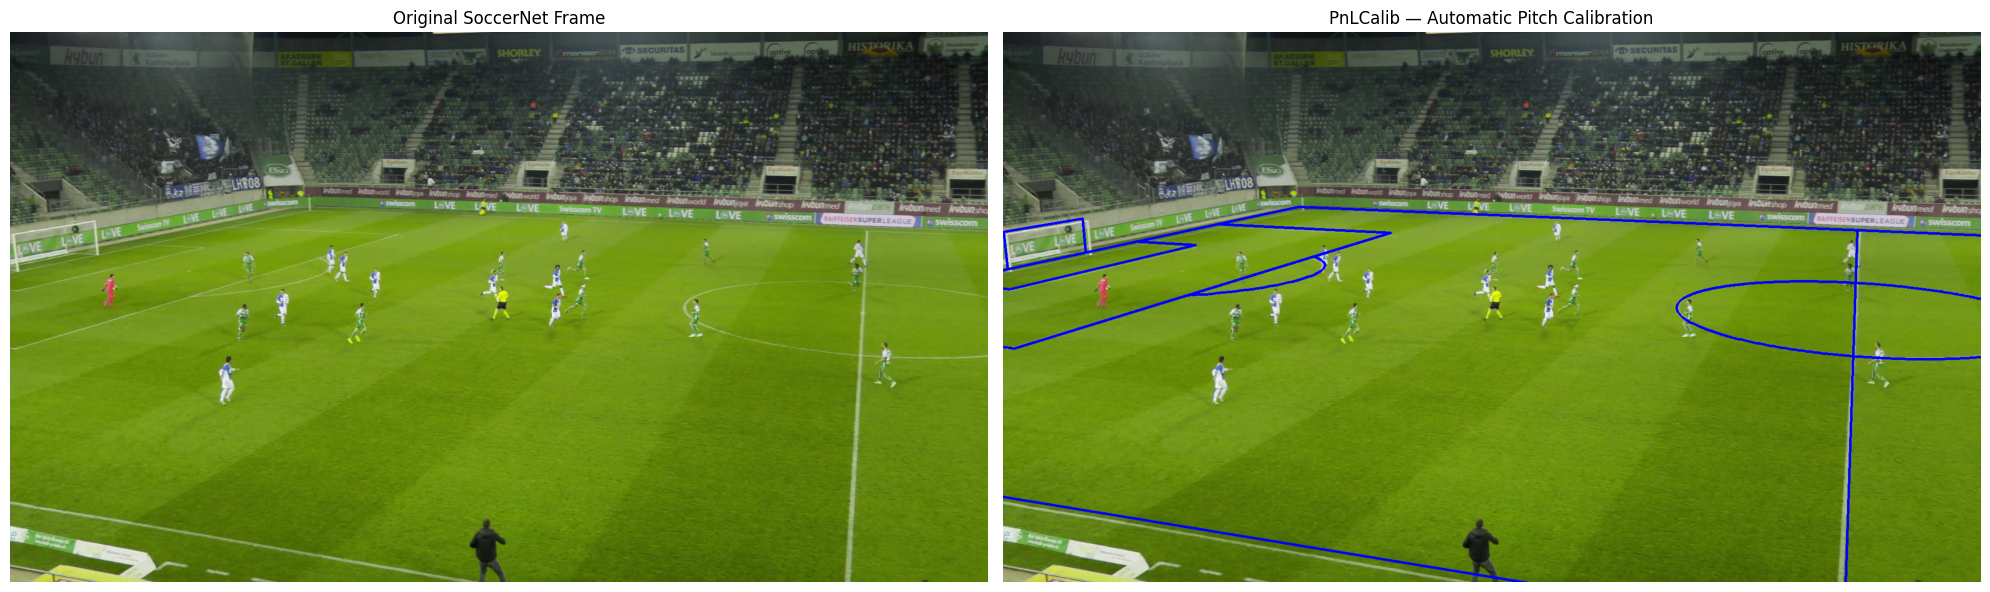

VISUAL OUTPUT CHECK
Mean absolute pixel difference: 2.649
Pixels changed (%): 1.7


In [8]:
from pathlib import Path
import cv2
import matplotlib.pyplot as plt

PROJECT_ROOT = Path("/content/drive/MyDrive/Football_CV_Project")

original_path = (
    PROJECT_ROOT
    / "data/raw/soccernet"
    / "SNMOT-066/img1/000376.jpg"
)

result_path = (
    PROJECT_ROOT
    / "outputs/calibration/v2.0/pnlcalib_smoke_test"
    / "SNMOT-066_000376_result.png"
)

original = cv2.imread(str(original_path))
result = cv2.imread(str(result_path))

assert original is not None, "Original image not found."
assert result is not None, "PnLCalib result not found."

original_rgb = cv2.cvtColor(original, cv2.COLOR_BGR2RGB)
result_rgb = cv2.cvtColor(result, cv2.COLOR_BGR2RGB)

fig, axes = plt.subplots(1, 2, figsize=(20, 7))

axes[0].imshow(original_rgb)
axes[0].set_title("Original SoccerNet Frame")
axes[0].axis("off")

axes[1].imshow(result_rgb)
axes[1].set_title("PnLCalib — Automatic Pitch Calibration")
axes[1].axis("off")

plt.tight_layout()
plt.show()

# Check whether the output differs from the original
difference = cv2.absdiff(original, result)

print("VISUAL OUTPUT CHECK")
print("=" * 55)
print("Mean absolute pixel difference:", round(float(difference.mean()), 3))
print("Pixels changed (%):", round(
    100 * float((difference.max(axis=2) > 10).mean()), 2
))

In [9]:
from pathlib import Path
import subprocess
import sys
import time
import json

PROJECT_ROOT = Path("/content/drive/MyDrive/Football_CV_Project")
DATA_ROOT = PROJECT_ROOT / "data/raw/soccernet"
OUTPUT_DIR = PROJECT_ROOT / "outputs/calibration/v2.0"
WEIGHTS_DIR = PROJECT_ROOT / "models/pnlcalib"
repo = Path("/content/PnLCalib")

evaluation_frames = {
    "SNMOT-060": [142, 235, 376, 514, 607],
    "SNMOT-066": [142, 328, 376, 467, 700],
    "SNMOT-069": [142, 235, 282, 376, 421]
}

benchmark_dir = OUTPUT_DIR / "pnlcalib_benchmark"
benchmark_dir.mkdir(parents=True, exist_ok=True)

results = []

print("PNLCALIB — CROSS-SEQUENCE BENCHMARK")
print("=" * 65)
print("Sequences:", len(evaluation_frames))
print("Total frames:", sum(map(len, evaluation_frames.values())))
print("Per-frame tuning: None")
print("Point-and-line refinement: Enabled")
print()

for sequence, frames in evaluation_frames.items():

    print(f"\n{sequence}")
    print("-" * 55)

    sequence_dir = benchmark_dir / sequence
    sequence_dir.mkdir(parents=True, exist_ok=True)

    for frame_number in frames:

        source = (
            DATA_ROOT / sequence / "img1"
            / f"{frame_number:06d}.jpg"
        )

        output = (
            sequence_dir
            / f"{frame_number:06d}_calibrated.png"
        )

        if not source.exists():
            print(f"Frame {frame_number}: SOURCE MISSING")
            results.append({
                "sequence": sequence,
                "frame": frame_number,
                "success": False,
                "error": "Source image missing"
            })
            continue

        command = [
            sys.executable,
            "inference.py",
            "--weights_kp", str(WEIGHTS_DIR / "SV_kp"),
            "--weights_line", str(WEIGHTS_DIR / "SV_lines"),
            "--pnl_refine",
            "--input_path", str(source),
            "--input_type", "image",
            "--save_path", str(output),
            "--device", "cuda:0"
        ]

        start = time.time()

        try:
            completed = subprocess.run(
                command,
                cwd=str(repo),
                capture_output=True,
                text=True,
                timeout=180
            )

            success = (
                completed.returncode == 0
                and output.exists()
            )

            elapsed = round(time.time() - start, 2)

            results.append({
                "sequence": sequence,
                "frame": frame_number,
                "success": success,
                "seconds": elapsed,
                "output": str(output) if success else None,
                "error": (
                    ""
                    if success
                    else (completed.stderr or completed.stdout)[-500:]
                )
            })

            print(
                f"Frame {frame_number}: "
                f"{'SUCCESS' if success else 'FAILED'} "
                f"({elapsed}s)"
            )

        except Exception as e:

            results.append({
                "sequence": sequence,
                "frame": frame_number,
                "success": False,
                "error": str(e)
            })

            print(f"Frame {frame_number}: ERROR — {e}")

manifest = benchmark_dir / "benchmark_results.json"

manifest.write_text(
    json.dumps(results, indent=2)
)

successful = sum(r["success"] for r in results)

print("\nBENCHMARK SUMMARY")
print("=" * 65)
print("Successful executions:", successful, "/", len(results))
print("Manifest:", manifest)
print("Results directory:", benchmark_dir)

PNLCALIB — CROSS-SEQUENCE BENCHMARK
Sequences: 3
Total frames: 15
Per-frame tuning: None
Point-and-line refinement: Enabled


SNMOT-060
-------------------------------------------------------
Frame 142: SUCCESS (10.86s)
Frame 235: SUCCESS (10.71s)
Frame 376: SUCCESS (10.75s)
Frame 514: SUCCESS (11.0s)
Frame 607: SUCCESS (11.03s)

SNMOT-066
-------------------------------------------------------
Frame 142: SUCCESS (10.85s)
Frame 328: SUCCESS (10.98s)
Frame 376: SUCCESS (10.36s)
Frame 467: SUCCESS (10.59s)
Frame 700: SUCCESS (11.63s)

SNMOT-069
-------------------------------------------------------
Frame 142: SUCCESS (10.9s)
Frame 235: SUCCESS (11.02s)
Frame 282: SUCCESS (10.67s)
Frame 376: SUCCESS (11.1s)
Frame 421: SUCCESS (10.73s)

BENCHMARK SUMMARY
Successful executions: 15 / 15
Manifest: /content/drive/MyDrive/Football_CV_Project/outputs/calibration/v2.0/pnlcalib_benchmark/benchmark_results.json
Results directory: /content/drive/MyDrive/Football_CV_Project/outputs/calibration/v2.0/

In [10]:
from pathlib import Path
import cv2
import matplotlib.pyplot as plt

PROJECT_ROOT = Path("/content/drive/MyDrive/Football_CV_Project")
DATA_ROOT = PROJECT_ROOT / "data/raw/soccernet"

benchmark_dir = (
    PROJECT_ROOT
    / "outputs/calibration/v2.0/pnlcalib_benchmark"
)

evaluation_frames = {
    "SNMOT-060": [142, 235, 376, 514, 607],
    "SNMOT-066": [142, 328, 376, 467, 700],
    "SNMOT-069": [142, 235, 282, 376, 421]
}

fig, axes = plt.subplots(
    3, 5,
    figsize=(25, 10),
    constrained_layout=True
)

for row, (sequence, frames) in enumerate(evaluation_frames.items()):
    for col, frame_number in enumerate(frames):

        image_path = (
            benchmark_dir
            / sequence
            / f"{frame_number:06d}_calibrated.png"
        )

        image = cv2.imread(str(image_path))

        ax = axes[row, col]

        if image is None:
            ax.text(
                0.5, 0.5,
                "MISSING RESULT",
                ha="center",
                va="center"
            )
        else:
            image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
            ax.imshow(image_rgb)

        ax.set_title(
            f"{sequence} | Frame {frame_number}",
            fontsize=11
        )
        ax.axis("off")

contact_sheet = benchmark_dir / "pnlcalib_15_frame_comparison.png"

fig.savefig(
    contact_sheet,
    dpi=150,
    bbox_inches="tight"
)

plt.show()

print("COMPARISON SHEET SAVED")
print("=" * 55)
print(contact_sheet)

Output hidden; open in https://colab.research.google.com to view.

In [11]:
from pathlib import Path
import ast

repo = Path("/content/PnLCalib")
inference_file = repo / "inference.py"

source = inference_file.read_text(
    encoding="utf-8",
    errors="ignore"
)

lines = source.splitlines()

print("PNLCALIB — CALIBRATION OUTPUT INSPECTION")
print("=" * 70)

keywords = [
    "FramebyFrameCalib",
    "homography",
    "camera",
    "calibrate",
    "projection",
    "pnl_refine",
    "save_path",
    "cv2.imwrite",
    "VideoWriter"
]

matches = set()

for i, line in enumerate(lines):
    if any(keyword.lower() in line.lower() for keyword in keywords):
        matches.add(i)

# Combine nearby matches into readable code blocks
intervals = []

for i in sorted(matches):
    start = max(0, i - 3)
    end = min(len(lines), i + 6)

    if intervals and start <= intervals[-1][1]:
        intervals[-1] = (
            intervals[-1][0],
            max(intervals[-1][1], end)
        )
    else:
        intervals.append((start, end))

for start, end in intervals:
    print(f"\n--- Lines {start + 1}–{end} ---")

    for i in range(start, end):
        print(f"{i + 1:4d}: {lines[i]}")

print("\nINSPECTION COMPLETE")
print("No files modified.")

PNLCALIB — CALIBRATION OUTPUT INSPECTION

--- Lines 14–22 ---
  14: from model.cls_hrnet import get_cls_net
  15: from model.cls_hrnet_l import get_cls_net as get_cls_net_l
  16: 
  17: from utils.utils_calib import FramebyFrameCalib, pan_tilt_roll_to_orientation
  18: from utils.utils_heatmap import get_keypoints_from_heatmap_batch_maxpool, get_keypoints_from_heatmap_batch_maxpool_l, \
  19:     complete_keypoints, coords_to_dict
  20: 
  21: 
  22: lines_coords = [[[0., 54.16, 0.], [16.5, 54.16, 0.]],

--- Lines 44–52 ---
  44:                 [[99.5, 24.84, 0.], [105., 24.84, 0.]]]
  45: 
  46: 
  47: def projection_from_cam_params(final_params_dict):
  48:     cam_params = final_params_dict["cam_params"]
  49:     x_focal_length = cam_params['x_focal_length']
  50:     y_focal_length = cam_params['y_focal_length']
  51:     principal_point = np.array(cam_params['principal_point'])
  52:     position_meters = np.array(cam_params['position_meters'])

--- Lines 62–70 ---
  62:     ret

In [12]:
from pathlib import Path

repo = Path("/content/PnLCalib")
source = (repo / "inference.py").read_text(
    encoding="utf-8",
    errors="ignore"
)

lines = source.splitlines()

print("PNLCALIB — CAMERA PROJECTION INSPECTION")
print("=" * 70)

print("\n1. PITCH REFERENCE COORDINATES")
print("-" * 70)

for i in range(20, min(47, len(lines))):
    print(f"{i+1:4d}: {lines[i]}")

print("\n2. CAMERA PROJECTION CONSTRUCTION")
print("-" * 70)

for i in range(46, min(64, len(lines))):
    print(f"{i+1:4d}: {lines[i]}")

print("\n3. PITCH PROJECTION AND RENDERING")
print("-" * 70)

for i in range(90, min(137, len(lines))):
    print(f"{i+1:4d}: {lines[i]}")

print("\nInspection complete. No files modified.")

PNLCALIB — CAMERA PROJECTION INSPECTION

1. PITCH REFERENCE COORDINATES
----------------------------------------------------------------------
  21: 
  22: lines_coords = [[[0., 54.16, 0.], [16.5, 54.16, 0.]],
  23:                 [[16.5, 13.84, 0.], [16.5, 54.16, 0.]],
  24:                 [[16.5, 13.84, 0.], [0., 13.84, 0.]],
  25:                 [[88.5, 54.16, 0.], [105., 54.16, 0.]],
  26:                 [[88.5, 13.84, 0.], [88.5, 54.16, 0.]],
  27:                 [[88.5, 13.84, 0.], [105., 13.84, 0.]],
  28:                 [[0., 37.66, -2.44], [0., 30.34, -2.44]],
  29:                 [[0., 37.66, 0.], [0., 37.66, -2.44]],
  30:                 [[0., 30.34, 0.], [0., 30.34, -2.44]],
  31:                 [[105., 37.66, -2.44], [105., 30.34, -2.44]],
  32:                 [[105., 30.34, 0.], [105., 30.34, -2.44]],
  33:                 [[105., 37.66, 0.], [105., 37.66, -2.44]],
  34:                 [[52.5, 0., 0.], [52.5, 68, 0.]],
  35:                 [[0., 68., 0.], [105

In [13]:
import numpy as np

PITCH_LENGTH = 105.0
PITCH_WIDTH = 68.0

def projection_to_homography(P):
    """
    Convert PnLCalib's 3x4 camera projection matrix
    into a ground-plane image-to-pitch homography.

    Pitch coordinates:
        X: 0 to 105 metres
        Y: 0 to 68 metres

    Returns:
        H_pitch_to_image
        H_image_to_pitch
    """

    P = np.asarray(P, dtype=np.float64)

    if P.shape != (3, 4):
        raise ValueError(
            f"Expected projection matrix (3,4), got {P.shape}"
        )

    # Extract the ground-plane projection (Z = 0)
    H_centered = P[:, [0, 1, 3]]

    # Convert corner-origin pitch coordinates
    # to PnLCalib's centered coordinates
    T = np.array([
        [1.0, 0.0, -PITCH_LENGTH / 2],
        [0.0, 1.0, -PITCH_WIDTH / 2],
        [0.0, 0.0, 1.0]
    ])

    H_pitch_to_image = H_centered @ T

    if not np.all(np.isfinite(H_pitch_to_image)):
        raise ValueError("Non-finite homography values.")

    if np.linalg.matrix_rank(H_pitch_to_image) < 3:
        raise ValueError("Homography is singular.")

    H_image_to_pitch = np.linalg.inv(H_pitch_to_image)

    # Normalize both matrices
    H_pitch_to_image /= H_pitch_to_image[2, 2]
    H_image_to_pitch /= H_image_to_pitch[2, 2]

    return H_pitch_to_image, H_image_to_pitch


def transform_points(points, H):
    """
    Transform 2D points using a 3x3 homography.
    """

    points = np.asarray(points, dtype=np.float64)

    if points.ndim != 2 or points.shape[1] != 2:
        raise ValueError("Points must have shape (N, 2).")

    homogeneous = np.column_stack([
        points,
        np.ones(len(points))
    ])

    projected = (H @ homogeneous.T).T

    denominators = projected[:, 2]

    if np.any(np.abs(denominators) < 1e-10):
        raise ValueError("Point projects to infinity.")

    return projected[:, :2] / denominators[:, None]


print("HOMOGRAPHY CONVERSION UTILITY")
print("=" * 60)

# Synthetic camera projection for mathematical testing
P_test = np.array([
    [900, 0, 960, 0],
    [0, 900, 540, 0],
    [0, 0, 1, 20]
], dtype=np.float64)

H_p2i, H_i2p = projection_to_homography(P_test)

test_points = np.array([
    [0, 0],
    [105, 0],
    [105, 68],
    [0, 68],
    [52.5, 34]
], dtype=np.float64)

image_points = transform_points(test_points, H_p2i)
recovered_points = transform_points(image_points, H_i2p)

error = np.linalg.norm(
    recovered_points - test_points,
    axis=1
)

print("Pitch dimensions:", PITCH_LENGTH, "×", PITCH_WIDTH, "m")
print("Homography shape:", H_i2p.shape)
print("Maximum round-trip error:", f"{error.max():.12f}", "m")

assert error.max() < 1e-6

print("\nConversion utility passed its mathematical test.")

HOMOGRAPHY CONVERSION UTILITY
Pitch dimensions: 105.0 × 68.0 m
Homography shape: (3, 3)
Maximum round-trip error: 0.000000000000 m

Conversion utility passed its mathematical test.


In [14]:
from pathlib import Path
import ast

repo = Path("/content/PnLCalib")
original_script = repo / "inference.py"

OUTPUT_DIR = Path(
    "/content/drive/MyDrive/Football_CV_Project/"
    "outputs/calibration/v2.0"
)

export_dir = OUTPUT_DIR / "pnlcalib_export"
export_dir.mkdir(parents=True, exist_ok=True)

source = original_script.read_text(
    encoding="utf-8",
    errors="ignore"
)

lines = source.splitlines()

print("PNLCALIB — EXPORTER PREPARATION")
print("=" * 65)

print("\n1. MODEL INITIALIZATION")
print("-" * 65)

for i in range(228, min(249, len(lines))):
    print(f"{i+1:4d}: {lines[i]}")

print("\n2. INFERENCE FUNCTION")
print("-" * 65)

for i in range(64, min(89, len(lines))):
    print(f"{i+1:4d}: {lines[i]}")

print("\n3. EXPORT DESTINATION")
print("-" * 65)

print(export_dir)

print("\n4. ORIGINAL REPOSITORY")
print("-" * 65)

print("Original inference script:", original_script)
print("Original file unchanged:", True)

print("\nReady to create a reusable calibration exporter.")

PNLCALIB — EXPORTER PREPARATION

1. MODEL INITIALIZATION
-----------------------------------------------------------------
 229:     line_threshold = args.line_threshold
 230: 
 231:     cfg = yaml.safe_load(open("config/hrnetv2_w48.yaml", 'r'))
 232:     cfg_l = yaml.safe_load(open("config/hrnetv2_w48_l.yaml", 'r'))
 233: 
 234:     loaded_state = torch.load(args.weights_kp, map_location=device)
 235:     model = get_cls_net(cfg)
 236:     model.load_state_dict(loaded_state)
 237:     model.to(device)
 238:     model.eval()
 239: 
 240:     loaded_state_l = torch.load(args.weights_line, map_location=device)
 241:     model_l = get_cls_net_l(cfg_l)
 242:     model_l.load_state_dict(loaded_state_l)
 243:     model_l.to(device)
 244:     model_l.eval()
 245: 
 246:     transform2 = T.Resize((540, 960))
 247: 
 248:     process_input(input_path, input_type, model_kp, model_line, kp_threshold, line_threshold, pnl_refine,
 249:                   save_path, display)

2. INFERENCE FUNCTION
--

In [15]:
from pathlib import Path
import sys
import json
import numpy as np
import cv2
import torch
import yaml

# -------------------------------------------------------
# 1. Project paths
# -------------------------------------------------------

PROJECT_ROOT = Path("/content/drive/MyDrive/Football_CV_Project")
DATA_ROOT = PROJECT_ROOT / "data/raw/soccernet"
WEIGHTS_DIR = PROJECT_ROOT / "models/pnlcalib"
OUTPUT_DIR = PROJECT_ROOT / "outputs/calibration/v2.0/pnlcalib_export"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

repo = Path("/content/PnLCalib")

if str(repo) not in sys.path:
    sys.path.insert(0, str(repo))

if str(repo / "sn_calibration") not in sys.path:
    sys.path.insert(0, str(repo / "sn_calibration"))

if str(repo / "sn_calibration" / "src") not in sys.path:
    sys.path.insert(0, str(repo / "sn_calibration" / "src"))

# -------------------------------------------------------
# 2. Import original PnLCalib inference functions
# -------------------------------------------------------

import importlib.util

spec = importlib.util.spec_from_file_location(
    "pnlcalib_inference",
    repo / "inference.py"
)

pnl = importlib.util.module_from_spec(spec)
spec.loader.exec_module(pnl)

from model.cls_hrnet import get_cls_net
from model.cls_hrnet_l import get_cls_net as get_cls_net_l
from utils.utils_calib import FramebyFrameCalib

# -------------------------------------------------------
# 3. Load models once
# -------------------------------------------------------

device = "cuda:0" if torch.cuda.is_available() else "cpu"

print("LOADING PNLCALIB MODELS")
print("=" * 60)

with open(repo / "config/hrnetv2_w48.yaml") as f:
    cfg = yaml.safe_load(f)

with open(repo / "config/hrnetv2_w48_l.yaml") as f:
    cfg_l = yaml.safe_load(f)

model_kp = get_cls_net(cfg)
model_line = get_cls_net_l(cfg_l)

model_kp.load_state_dict(
    torch.load(
        WEIGHTS_DIR / "SV_kp",
        map_location="cpu",
        weights_only=True
    )
)

model_line.load_state_dict(
    torch.load(
        WEIGHTS_DIR / "SV_lines",
        map_location="cpu",
        weights_only=True
    )
)

model_kp.to(device).eval()
model_line.to(device).eval()

# Original PnLCalib inference() uses these globals.
pnl.device = device
pnl.transform2 = pnl.T.Resize((540, 960))

print("Keypoint model: Loaded")
print("Line model: Loaded")
print("Device:", device)

# -------------------------------------------------------
# 4. Homography conversion
# -------------------------------------------------------

PITCH_LENGTH = 105.0
PITCH_WIDTH = 68.0

def projection_to_homography(P):

    P = np.asarray(P, dtype=np.float64)

    if P.shape != (3, 4):
        raise ValueError("Projection must be 3x4.")

    H_centered = P[:, [0, 1, 3]]

    offset = np.array([
        [1, 0, -PITCH_LENGTH / 2],
        [0, 1, -PITCH_WIDTH / 2],
        [0, 0, 1]
    ], dtype=np.float64)

    H_pitch_to_image = H_centered @ offset

    if not np.all(np.isfinite(H_pitch_to_image)):
        raise ValueError("Non-finite homography.")

    if np.linalg.matrix_rank(H_pitch_to_image) != 3:
        raise ValueError("Singular homography.")

    H_image_to_pitch = np.linalg.inv(H_pitch_to_image)

    # Normalize using matrix norm rather than assuming H[2,2] != 0.
    H_pitch_to_image /= np.linalg.norm(H_pitch_to_image)
    H_image_to_pitch /= np.linalg.norm(H_image_to_pitch)

    return H_pitch_to_image, H_image_to_pitch

# -------------------------------------------------------
# 5. Reusable calibration function
# -------------------------------------------------------

def calibrate_frame(image_path):

    frame = cv2.imread(str(image_path))

    if frame is None:
        raise FileNotFoundError(image_path)

    height, width = frame.shape[:2]

    # Fresh camera object avoids carrying state between
    # independent images or different sequences.
    cam = FramebyFrameCalib(
        iwidth=width,
        iheight=height,
        denormalize=True
    )

    params = pnl.inference(
        cam,
        frame,
        model_kp,
        model_line,
        kp_threshold=0.3434,
        line_threshold=0.7867,
        pnl_refine=True
    )

    if params is None:
        return None, None, None, frame

    P = pnl.projection_from_cam_params(params)

    H_p2i, H_i2p = projection_to_homography(P)

    return params, H_p2i, H_i2p, frame

# -------------------------------------------------------
# 6. Test on real SoccerNet frame
# -------------------------------------------------------

sequence = "SNMOT-066"
frame_number = 376

image_path = (
    DATA_ROOT / sequence / "img1" /
    f"{frame_number:06d}.jpg"
)

print("\nREAL-FRAME CALIBRATION TEST")
print("=" * 60)

params, H_p2i, H_i2p, frame = calibrate_frame(image_path)

if params is None:
    print("Calibration could not be estimated.")
else:

    print("Camera parameters: Estimated")
    print("Pitch-to-image homography shape:", H_p2i.shape)
    print("Image-to-pitch homography shape:", H_i2p.shape)

    # Test real-matrix round-trip consistency.
    points = np.array([
        [0, 0],
        [105, 0],
        [105, 68],
        [0, 68],
        [52.5, 34]
    ], dtype=np.float64)

    def apply_homography(points, H):
        pts = cv2.perspectiveTransform(
            points.reshape(-1, 1, 2),
            H
        )
        return pts.reshape(-1, 2)

    image_points = apply_homography(points, H_p2i)
    recovered = apply_homography(image_points, H_i2p)

    roundtrip_error = np.linalg.norm(
        recovered - points,
        axis=1
    ).max()

    print("Round-trip error:", roundtrip_error, "m")

    # Save numerical matrices.
    save_path = OUTPUT_DIR / f"{sequence}_{frame_number:06d}_calibration.npz"

    np.savez_compressed(
        save_path,
        H_pitch_to_image=H_p2i,
        H_image_to_pitch=H_i2p,
        projection_matrix=pnl.projection_from_cam_params(params),
        sequence=sequence,
        frame_number=frame_number,
        pitch_length=PITCH_LENGTH,
        pitch_width=PITCH_WIDTH
    )

    print("Saved:", save_path)

    # Draw using PnLCalib's original visualization.
    projected = pnl.project(
        frame.copy(),
        pnl.projection_from_cam_params(params)
    )

    output_image = OUTPUT_DIR / f"{sequence}_{frame_number:06d}_overlay.png"

    cv2.imwrite(str(output_image), projected)

    print("Overlay saved:", output_image)

print("\nCell 25 completed.")

LOADING PNLCALIB MODELS
Keypoint model: Loaded
Line model: Loaded
Device: cuda:0

REAL-FRAME CALIBRATION TEST
Camera parameters: Estimated
Pitch-to-image homography shape: (3, 3)
Image-to-pitch homography shape: (3, 3)
Round-trip error: 4.432605725799687e-14 m
Saved: /content/drive/MyDrive/Football_CV_Project/outputs/calibration/v2.0/pnlcalib_export/SNMOT-066_000376_calibration.npz
Overlay saved: /content/drive/MyDrive/Football_CV_Project/outputs/calibration/v2.0/pnlcalib_export/SNMOT-066_000376_overlay.png

Cell 25 completed.


In [16]:
import numpy as np
import cv2
from pathlib import Path

PROJECT_ROOT = Path("/content/drive/MyDrive/Football_CV_Project")

calibration_file = (
    PROJECT_ROOT
    / "outputs/calibration/v2.0/pnlcalib_export"
    / "SNMOT-066_000376_calibration.npz"
)

with np.load(calibration_file) as data:
    H_i2p = data["H_image_to_pitch"]
    H_p2i = data["H_pitch_to_image"]
    pitch_length = float(data["pitch_length"])
    pitch_width = float(data["pitch_width"])

image_width = 1920
image_height = 1080

def project_points(points, H):
    points = np.asarray(points, dtype=np.float64)
    return cv2.perspectiveTransform(
        points.reshape(-1, 1, 2),
        H.astype(np.float64)
    ).reshape(-1, 2)

print("PNLCALIB — GEOMETRIC VALIDATION")
print("=" * 65)

# 1. Project the four pitch corners into the image
pitch_corners = np.array([
    [0, 0],
    [pitch_length, 0],
    [pitch_length, pitch_width],
    [0, pitch_width]
], dtype=np.float64)

image_corners = project_points(pitch_corners, H_p2i)

print("\n1. PROJECTED PITCH CORNERS")
print("-" * 65)

for i, corner in enumerate(image_corners):
    print(f"Corner {i+1}: {corner.round(2)}")

# 2. Map a grid of image points onto the pitch
xs = np.linspace(0, image_width - 1, 9)
ys = np.linspace(0, image_height - 1, 7)

grid = np.array([
    [x, y]
    for y in ys
    for x in xs
], dtype=np.float64)

mapped = project_points(grid, H_i2p)

finite = np.isfinite(mapped).all(axis=1)

inside_pitch = (
    finite
    & (mapped[:, 0] >= 0)
    & (mapped[:, 0] <= pitch_length)
    & (mapped[:, 1] >= 0)
    & (mapped[:, 1] <= pitch_width)
)

print("\n2. IMAGE-TO-PITCH MAPPING")
print("-" * 65)

print("Sampled image points:", len(grid))
print("Finite mapped points:", int(finite.sum()))
print("Points inside pitch:", int(inside_pitch.sum()))

print(
    "Inside-pitch percentage:",
    round(100 * inside_pitch.mean(), 2),
    "%"
)

# 3. Round-trip consistency
recovered = project_points(mapped[finite], H_p2i)

errors = np.linalg.norm(
    recovered - grid[finite],
    axis=1
)

print("\n3. NUMERICAL CONSISTENCY")
print("-" * 65)

print("Median round-trip error:", np.median(errors), "pixels")
print("Maximum round-trip error:", np.max(errors), "pixels")

# 4. Matrix properties
print("\n4. MATRIX CHECKS")
print("-" * 65)

print("All values finite:", np.isfinite(H_i2p).all())
print("Matrix rank:", np.linalg.matrix_rank(H_i2p))
print("Determinant:", np.linalg.det(H_i2p))

print("\nVALIDATION COMPLETE")
print("These checks are diagnostic, not an accuracy score.")

PNLCALIB — GEOMETRIC VALIDATION

1. PROJECTED PITCH CORNERS
-----------------------------------------------------------------
Corner 1: [580.74 343.87]
Corner 2: [3331.43  456.98]
Corner 3: [24155.78  4866.87]
Corner 4: [-1186.57   719.39]

2. IMAGE-TO-PITCH MAPPING
-----------------------------------------------------------------
Sampled image points: 63
Finite mapped points: 63
Points inside pitch: 33
Inside-pitch percentage: 52.38 %

3. NUMERICAL CONSISTENCY
-----------------------------------------------------------------
Median round-trip error: 2.898457019905882e-13 pixels
Maximum round-trip error: 1.6077746776921857e-12 pixels

4. MATRIX CHECKS
-----------------------------------------------------------------
All values finite: True
Matrix rank: 3
Determinant: 5.071695791060589e-09

VALIDATION COMPLETE
These checks are diagnostic, not an accuracy score.


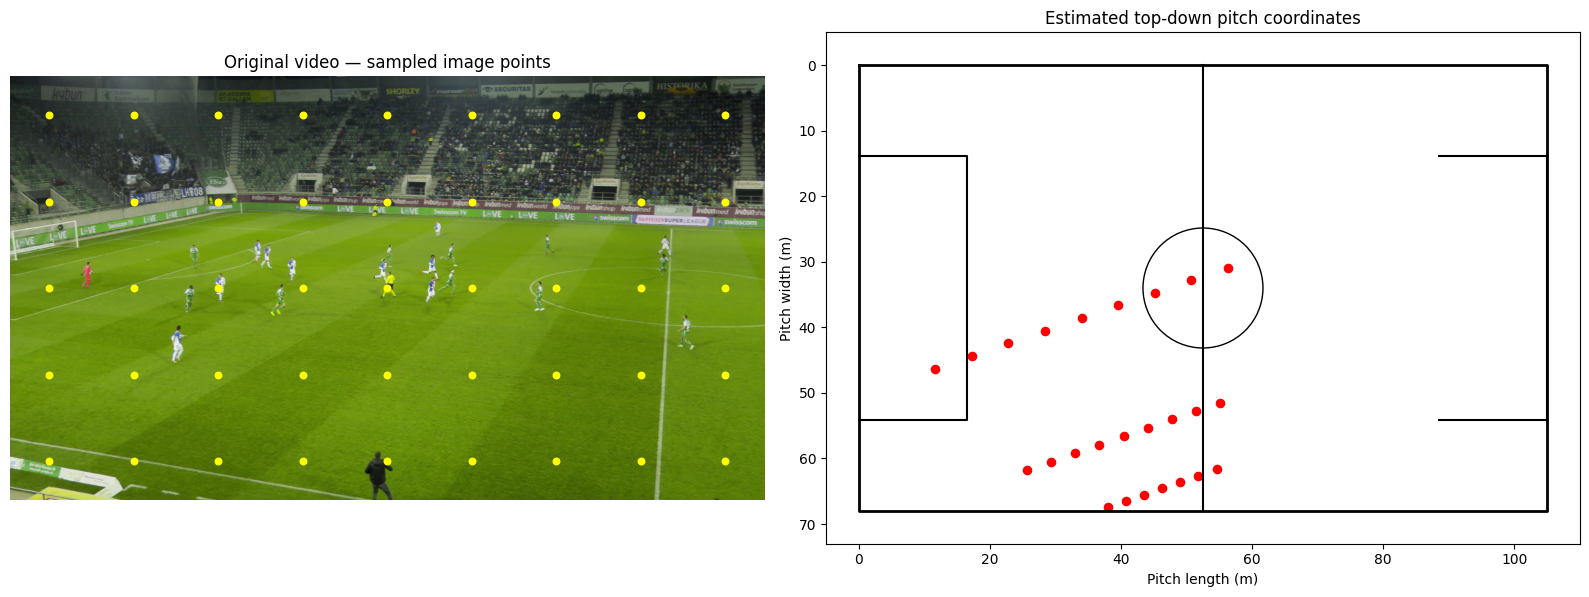

Diagnostic saved: /content/drive/MyDrive/Football_CV_Project/outputs/calibration/v2.0/pnlcalib_export/SNMOT-066_000376_mapping_diagnostic.png
Image points sampled: 45
Points inside pitch: 25


In [17]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
from pathlib import Path

PROJECT_ROOT = Path("/content/drive/MyDrive/Football_CV_Project")

sequence = "SNMOT-066"
frame_number = 376

image_path = (
    PROJECT_ROOT / "data/raw/soccernet"
    / sequence / "img1"
    / f"{frame_number:06d}.jpg"
)

calibration_path = (
    PROJECT_ROOT / "outputs/calibration/v2.0"
    / "pnlcalib_export"
    / f"{sequence}_{frame_number:06d}_calibration.npz"
)

with np.load(calibration_path) as data:
    H_i2p = data["H_image_to_pitch"]
    H_p2i = data["H_pitch_to_image"]

frame = cv2.imread(str(image_path))

if frame is None:
    raise FileNotFoundError(image_path)

height, width = frame.shape[:2]

# -------------------------------------------------------
# Sample a grid of image positions
# -------------------------------------------------------

xs = np.linspace(100, width - 100, 9)
ys = np.linspace(100, height - 100, 5)

image_points = np.array([
    [x, y]
    for y in ys
    for x in xs
], dtype=np.float64)

pitch_points = cv2.perspectiveTransform(
    image_points.reshape(-1, 1, 2),
    H_i2p
).reshape(-1, 2)

# -------------------------------------------------------
# Prepare pitch diagram
# -------------------------------------------------------

fig, axes = plt.subplots(
    1, 2,
    figsize=(16, 7)
)

# Original image
axes[0].imshow(
    cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
)

axes[0].scatter(
    image_points[:, 0],
    image_points[:, 1],
    c="yellow",
    s=22
)

axes[0].set_title(
    "Original video — sampled image points"
)

axes[0].axis("off")

# Top-down pitch
ax = axes[1]

ax.set_xlim(-5, 110)
ax.set_ylim(73, -5)
ax.set_aspect("equal")

# Pitch outline
ax.plot(
    [0, 105, 105, 0, 0],
    [0, 0, 68, 68, 0],
    color="black",
    linewidth=2
)

# Halfway line
ax.plot(
    [52.5, 52.5],
    [0, 68],
    color="black"
)

# Center circle
circle = plt.Circle(
    (52.5, 34),
    9.15,
    fill=False,
    color="black"
)

ax.add_patch(circle)

# Penalty areas
for x0, x1 in [(0, 16.5), (88.5, 105)]:
    ax.plot(
        [x0, x1, x1, x0],
        [13.84, 13.84, 54.16, 54.16],
        color="black"
    )

# Only display points inside pitch boundaries
inside = (
    (pitch_points[:, 0] >= 0)
    & (pitch_points[:, 0] <= 105)
    & (pitch_points[:, 1] >= 0)
    & (pitch_points[:, 1] <= 68)
)

ax.scatter(
    pitch_points[inside, 0],
    pitch_points[inside, 1],
    c="red",
    s=35
)

ax.set_title(
    "Estimated top-down pitch coordinates"
)

ax.set_xlabel("Pitch length (m)")
ax.set_ylabel("Pitch width (m)")

plt.tight_layout()

save_path = (
    PROJECT_ROOT
    / "outputs/calibration/v2.0"
    / "pnlcalib_export"
    / "SNMOT-066_000376_mapping_diagnostic.png"
)

plt.savefig(
    save_path,
    dpi=150,
    bbox_inches="tight"
)

plt.show()

print("Diagnostic saved:", save_path)
print("Image points sampled:", len(image_points))
print("Points inside pitch:", int(inside.sum()))

In [18]:
import json
import time
import numpy as np
from pathlib import Path

PROJECT_ROOT = Path("/content/drive/MyDrive/Football_CV_Project")
DATA_ROOT = PROJECT_ROOT / "data/raw/soccernet"
EXPORT_DIR = (
    PROJECT_ROOT / "outputs/calibration/v2.0"
    / "pnlcalib_export"
)

EXPORT_DIR.mkdir(parents=True, exist_ok=True)

benchmark_frames = {
    "SNMOT-060": [142, 235, 376, 514, 607],
    "SNMOT-066": [142, 328, 376, 467, 700],
    "SNMOT-069": [142, 235, 282, 376, 421]
}

results = []
start_time = time.time()

print("PNLCALIB — MULTI-FRAME NUMERICAL EXPORT")
print("=" * 70)

for sequence, frame_numbers in benchmark_frames.items():

    print(f"\nSequence: {sequence}")

    for frame_number in frame_numbers:

        image_path = (
            DATA_ROOT / sequence / "img1"
            / f"{frame_number:06d}.jpg"
        )

        record = {
            "sequence": sequence,
            "frame": frame_number,
            "status": "failed"
        }

        try:
            params, H_p2i, H_i2p, frame = calibrate_frame(
                image_path
            )

            if params is None:
                record["reason"] = "No camera estimate"

            else:
                # Check numerical validity
                if not (
                    np.isfinite(H_p2i).all()
                    and np.isfinite(H_i2p).all()
                ):
                    raise ValueError("Non-finite homography")

                if np.linalg.matrix_rank(H_i2p) != 3:
                    raise ValueError("Singular homography")

                save_path = (
                    EXPORT_DIR
                    / f"{sequence}_{frame_number:06d}_calibration.npz"
                )

                np.savez_compressed(
                    save_path,
                    H_pitch_to_image=H_p2i,
                    H_image_to_pitch=H_i2p,
                    projection_matrix=(
                        pnl.projection_from_cam_params(params)
                    ),
                    sequence=sequence,
                    frame_number=frame_number,
                    pitch_length=105.0,
                    pitch_width=68.0
                )

                record["status"] = "exported"
                record["file"] = str(save_path)

                print(
                    f"  Frame {frame_number:04d}: "
                    "exported"
                )

        except Exception as e:
            record["reason"] = str(e)

            print(
                f"  Frame {frame_number:04d}: "
                f"FAILED — {e}"
            )

        results.append(record)

# Save manifest
manifest_path = EXPORT_DIR / "benchmark_export_manifest.json"

with open(manifest_path, "w") as f:
    json.dump(results, f, indent=2)

successes = sum(
    r["status"] == "exported"
    for r in results
)

elapsed = time.time() - start_time

print("\n" + "=" * 70)
print("EXPORT SUMMARY")
print("=" * 70)

print("Frames attempted:", len(results))
print("Successful exports:", successes)
print("Failed exports:", len(results) - successes)
print("Elapsed time:", round(elapsed, 1), "seconds")
print("Manifest:", manifest_path)

print("\nCell 28 completed.")

PNLCALIB — MULTI-FRAME NUMERICAL EXPORT

Sequence: SNMOT-060
  Frame 0142: exported
  Frame 0235: exported
  Frame 0376: exported
  Frame 0514: exported
  Frame 0607: exported

Sequence: SNMOT-066
  Frame 0142: exported
  Frame 0328: exported
  Frame 0376: exported
  Frame 0467: exported
  Frame 0700: exported

Sequence: SNMOT-069
  Frame 0142: exported
  Frame 0235: exported
  Frame 0282: exported
  Frame 0376: exported
  Frame 0421: exported

EXPORT SUMMARY
Frames attempted: 15
Successful exports: 15
Failed exports: 0
Elapsed time: 12.2 seconds
Manifest: /content/drive/MyDrive/Football_CV_Project/outputs/calibration/v2.0/pnlcalib_export/benchmark_export_manifest.json

Cell 28 completed.


In [19]:
import numpy as np
import json
import time
from pathlib import Path

PROJECT_ROOT = Path("/content/drive/MyDrive/Football_CV_Project")
DATA_ROOT = PROJECT_ROOT / "data/raw/soccernet"

EXPORT_DIR = (
    PROJECT_ROOT
    / "outputs/calibration/v2.0"
    / "pnlcalib_export"
    / "temporal_test"
)

EXPORT_DIR.mkdir(parents=True, exist_ok=True)

sequence = "SNMOT-066"
frame_numbers = range(350, 380)

records = []
start = time.time()

print("PNLCALIB — CONTINUOUS CALIBRATION TEST")
print("=" * 65)

for frame_number in frame_numbers:

    image_path = (
        DATA_ROOT / sequence / "img1"
        / f"{frame_number:06d}.jpg"
    )

    record = {
        "sequence": sequence,
        "frame": frame_number,
        "status": "failed"
    }

    try:
        params, H_p2i, H_i2p, frame = calibrate_frame(
            image_path
        )

        if params is None:
            record["reason"] = "No camera estimate"

        else:
            if not (
                np.isfinite(H_p2i).all()
                and np.isfinite(H_i2p).all()
            ):
                raise ValueError("Non-finite homography")

            if np.linalg.matrix_rank(H_i2p) != 3:
                raise ValueError("Singular homography")

            save_path = (
                EXPORT_DIR
                / f"{sequence}_{frame_number:06d}.npz"
            )

            np.savez_compressed(
                save_path,
                H_pitch_to_image=H_p2i,
                H_image_to_pitch=H_i2p,
                projection_matrix=(
                    pnl.projection_from_cam_params(params)
                ),
                sequence=sequence,
                frame_number=frame_number,
                pitch_length=105.0,
                pitch_width=68.0
            )

            record["status"] = "exported"
            record["file"] = str(save_path)

    except Exception as e:
        record["reason"] = str(e)

    records.append(record)

    print(
        f"Frame {frame_number}: "
        f"{record['status']}"
    )

elapsed = time.time() - start

manifest_path = EXPORT_DIR / "temporal_manifest.json"

with open(manifest_path, "w") as f:
    json.dump(records, f, indent=2)

successful = sum(
    r["status"] == "exported"
    for r in records
)

print("\n" + "=" * 65)
print("TEMPORAL TEST SUMMARY")
print("=" * 65)

print("Frames:", len(records))
print("Successful:", successful)
print("Failed:", len(records) - successful)
print("Success rate:", round(100 * successful / len(records), 2), "%")
print("Elapsed:", round(elapsed, 2), "seconds")
print("Average:", round(elapsed / len(records), 2), "seconds/frame")
print("Manifest:", manifest_path)

PNLCALIB — CONTINUOUS CALIBRATION TEST
Frame 350: exported
Frame 351: exported
Frame 352: exported
Frame 353: exported
Frame 354: exported
Frame 355: exported
Frame 356: exported
Frame 357: exported
Frame 358: exported
Frame 359: exported
Frame 360: exported
Frame 361: exported
Frame 362: exported
Frame 363: exported
Frame 364: exported
Frame 365: exported
Frame 366: exported
Frame 367: exported
Frame 368: exported
Frame 369: exported
Frame 370: exported
Frame 371: exported
Frame 372: exported
Frame 373: exported
Frame 374: exported
Frame 375: exported
Frame 376: exported
Frame 377: exported
Frame 378: exported
Frame 379: exported

TEMPORAL TEST SUMMARY
Frames: 30
Successful: 30
Failed: 0
Success rate: 100.0 %
Elapsed: 34.48 seconds
Average: 1.15 seconds/frame
Manifest: /content/drive/MyDrive/Football_CV_Project/outputs/calibration/v2.0/pnlcalib_export/temporal_test/temporal_manifest.json


PNLCALIB — TEMPORAL STABILITY
350->351: 107 points | median=0.162 m | P90=0.409 m
351->352: 111 points | median=0.353 m | P90=0.630 m
352->353: 122 points | median=0.233 m | P90=0.469 m
353->354: 125 points | median=0.253 m | P90=0.435 m
354->355: 134 points | median=0.311 m | P90=0.705 m
355->356: 137 points | median=0.321 m | P90=0.489 m
356->357: 135 points | median=0.240 m | P90=0.501 m
357->358: 130 points | median=0.272 m | P90=0.587 m
358->359: 119 points | median=0.226 m | P90=0.343 m
359->360: 122 points | median=0.229 m | P90=0.622 m
360->361: 131 points | median=0.249 m | P90=0.475 m
361->362: 131 points | median=0.239 m | P90=0.368 m
362->363: 119 points | median=0.311 m | P90=0.504 m
363->364: 119 points | median=0.296 m | P90=0.458 m
364->365: 111 points | median=0.380 m | P90=0.587 m
365->366: 114 points | median=1.240 m | P90=2.514 m
366->367: 128 points | median=1.241 m | P90=1.998 m
367->368: 129 points | median=0.306 m | P90=0.506 m
368->369: 124 points | median=0.38

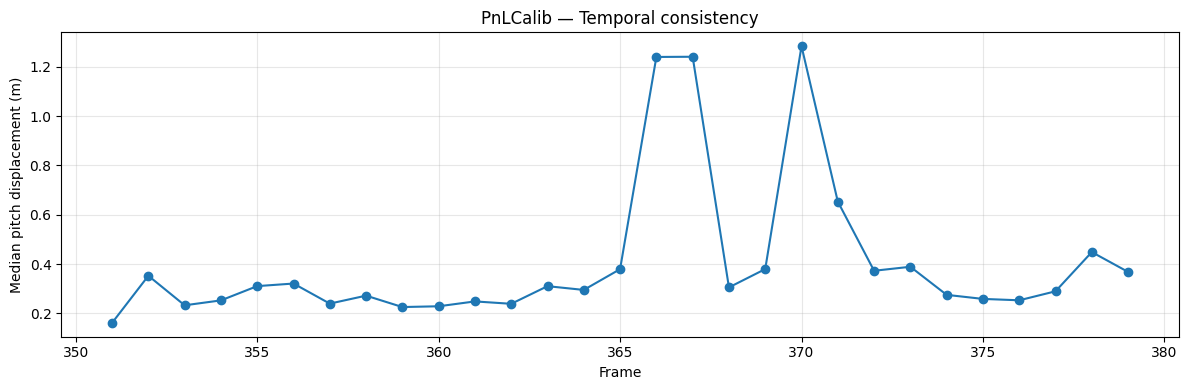

Plot saved: /content/drive/MyDrive/Football_CV_Project/outputs/calibration/v2.0/pnlcalib_export/temporal_test/temporal_stability.png


In [20]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

PROJECT_ROOT = Path("/content/drive/MyDrive/Football_CV_Project")
DATA_ROOT = PROJECT_ROOT / "data/raw/soccernet"

EXPORT_DIR = (
    PROJECT_ROOT
    / "outputs/calibration/v2.0"
    / "pnlcalib_export/temporal_test"
)

sequence = "SNMOT-066"
frames = list(range(350, 380))

def load_homography(frame_number):
    path = EXPORT_DIR / f"{sequence}_{frame_number:06d}.npz"
    with np.load(path) as data:
        return data["H_image_to_pitch"].astype(np.float64)

def image_to_pitch(points, H):
    return cv2.perspectiveTransform(
        np.asarray(points, dtype=np.float64).reshape(-1, 1, 2),
        H
    ).reshape(-1, 2)

def grass_mask(image):
    hsv = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)
    return cv2.inRange(
        hsv,
        np.array([30, 35, 25]),
        np.array([95, 255, 255])
    )

results = []

print("PNLCALIB — TEMPORAL STABILITY")
print("=" * 68)

for f1, f2 in zip(frames[:-1], frames[1:]):

    img1 = cv2.imread(
        str(DATA_ROOT / sequence / "img1" / f"{f1:06d}.jpg")
    )
    img2 = cv2.imread(
        str(DATA_ROOT / sequence / "img1" / f"{f2:06d}.jpg")
    )

    if img1 is None or img2 is None:
        raise FileNotFoundError(f"Missing image in pair {f1}-{f2}")

    gray1 = cv2.cvtColor(img1, cv2.COLOR_BGR2GRAY)
    gray2 = cv2.cvtColor(img2, cv2.COLOR_BGR2GRAY)

    mask1 = grass_mask(img1)
    mask2 = grass_mask(img2)

    # Detect trackable features on the grass.
    features = cv2.goodFeaturesToTrack(
        gray1,
        maxCorners=800,
        qualityLevel=0.01,
        minDistance=10,
        mask=mask1
    )

    if features is None or len(features) < 10:
        print(f"{f1}->{f2}: insufficient features")
        continue

    # Track features between frames.
    next_features, status, _ = cv2.calcOpticalFlowPyrLK(
        gray1, gray2, features, None,
        winSize=(21, 21),
        maxLevel=3
    )

    if next_features is None:
        continue

    valid = status.reshape(-1) == 1

    p1 = features.reshape(-1, 2)[valid]
    p2 = next_features.reshape(-1, 2)[valid]

    if len(p1) < 10:
        continue

    # Keep features that remain inside the image.
    h, w = gray2.shape

    inside_image = (
        (p2[:, 0] >= 0) &
        (p2[:, 0] < w) &
        (p2[:, 1] >= 0) &
        (p2[:, 1] < h)
    )

    p1 = p1[inside_image]
    p2 = p2[inside_image]

    if len(p1) < 10:
        continue

    # Keep points that remain on green grass.
    xy = np.rint(p2).astype(int)
    xy[:, 0] = np.clip(xy[:, 0], 0, w - 1)
    xy[:, 1] = np.clip(xy[:, 1], 0, h - 1)

    on_grass = mask2[xy[:, 1], xy[:, 0]] > 0

    p1 = p1[on_grass]
    p2 = p2[on_grass]

    if len(p1) < 10:
        continue

    H1 = load_homography(f1)
    H2 = load_homography(f2)

    pitch1 = image_to_pitch(p1, H1)
    pitch2 = image_to_pitch(p2, H2)

    valid_pitch = (
        np.isfinite(pitch1).all(axis=1) &
        np.isfinite(pitch2).all(axis=1) &
        (pitch1[:, 0] >= 0) &
        (pitch1[:, 0] <= 105) &
        (pitch1[:, 1] >= 0) &
        (pitch1[:, 1] <= 68) &
        (pitch2[:, 0] >= 0) &
        (pitch2[:, 0] <= 105) &
        (pitch2[:, 1] >= 0) &
        (pitch2[:, 1] <= 68)
    )

    pitch1 = pitch1[valid_pitch]
    pitch2 = pitch2[valid_pitch]

    if len(pitch1) < 10:
        print(f"{f1}->{f2}: insufficient pitch points")
        continue

    distances = np.linalg.norm(
        pitch2 - pitch1,
        axis=1
    )

    median_error = float(np.median(distances))
    p90_error = float(np.percentile(distances, 90))

    results.append({
        "frame1": f1,
        "frame2": f2,
        "tracked_points": len(distances),
        "median_error_m": median_error,
        "p90_error_m": p90_error
    })

    print(
        f"{f1}->{f2}: "
        f"{len(distances):3d} points | "
        f"median={median_error:.3f} m | "
        f"P90={p90_error:.3f} m"
    )

print("\n" + "=" * 68)
print("SUMMARY")
print("=" * 68)

if results:
    medians = [r["median_error_m"] for r in results]

    print("Frame pairs evaluated:", len(results))
    print("Median of pairwise errors:", round(float(np.median(medians)), 3), "m")
    print("Worst pairwise median:", round(float(np.max(medians)), 3), "m")

    plt.figure(figsize=(12, 4))
    plt.plot(
        [r["frame2"] for r in results],
        medians,
        marker="o"
    )
    plt.xlabel("Frame")
    plt.ylabel("Median pitch displacement (m)")
    plt.title("PnLCalib — Temporal consistency")
    plt.grid(alpha=0.3)
    plt.tight_layout()

    plot_path = EXPORT_DIR / "temporal_stability.png"
    plt.savefig(plot_path, dpi=150)
    plt.show()

    print("Plot saved:", plot_path)
else:
    print("No valid frame pairs evaluated.")

PNLCALIB — CAMERA MOTION CONSISTENCY
350->351 | points=107 | motion=2.98px | residual=3.80px
351->352 | points=111 | motion=2.94px | residual=9.23px
352->353 | points=122 | motion=3.08px | residual=4.84px
353->354 | points=125 | motion=3.30px | residual=6.18px
354->355 | points=134 | motion=3.03px | residual=5.24px
355->356 | points=137 | motion=3.21px | residual=4.58px
356->357 | points=135 | motion=3.09px | residual=5.98px
357->358 | points=130 | motion=2.53px | residual=6.02px
358->359 | points=119 | motion=2.58px | residual=3.79px
359->360 | points=122 | motion=2.66px | residual=4.83px
360->361 | points=131 | motion=2.50px | residual=4.34px
361->362 | points=131 | motion=2.77px | residual=4.93px
362->363 | points=119 | motion=2.59px | residual=9.02px
363->364 | points=119 | motion=2.85px | residual=4.90px
364->365 | points=111 | motion=2.99px | residual=8.94px
365->366 | points=114 | motion=3.03px | residual=28.29px
366->367 | points=128 | motion=2.98px | residual=8.53px
367->368 |

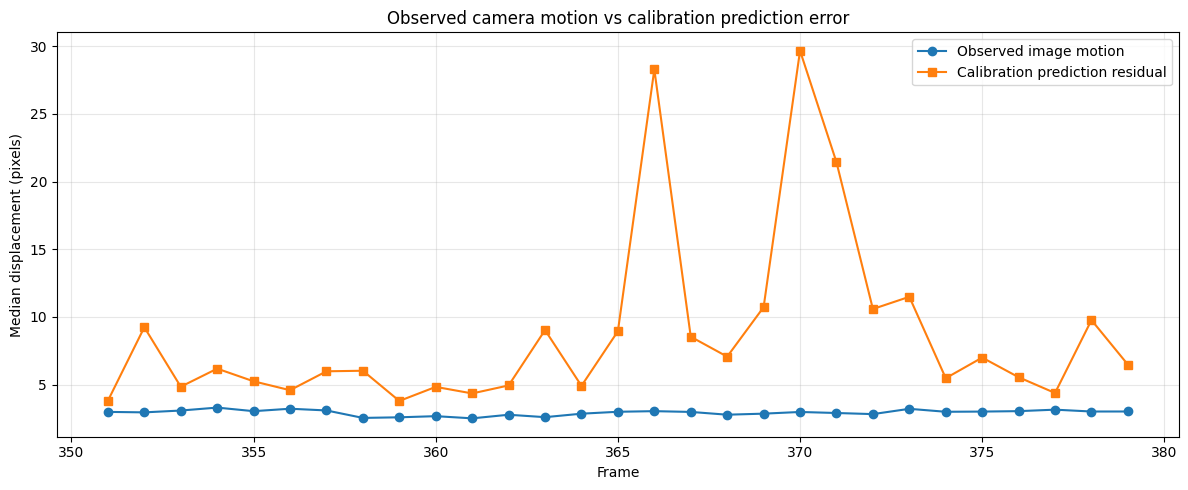


SUMMARY
Transitions evaluated: 29
Median calibration residual: 6.175 pixels
Maximum pairwise median residual: 29.67 pixels

Largest residual transitions:
369->370: 29.67px
365->366: 28.29px
370->371: 21.43px
372->373: 11.48px
368->369: 10.72px

Plot saved: /content/drive/MyDrive/Football_CV_Project/outputs/calibration/v2.0/pnlcalib_export/temporal_test/camera_motion_consistency.png


In [21]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# --------------------------------------------------
# 1. Paths
# --------------------------------------------------

PROJECT_ROOT = Path("/content/drive/MyDrive/Football_CV_Project")

DATA_ROOT = PROJECT_ROOT / "data/raw/soccernet"

CALIB_DIR = (
    PROJECT_ROOT
    / "outputs/calibration/v2.0"
    / "pnlcalib_export/temporal_test"
)

SEQUENCE = "SNMOT-066"
FRAMES = range(350, 380)

# --------------------------------------------------
# 2. Helper functions
# --------------------------------------------------

def load_frame(frame_number):
    path = (
        DATA_ROOT / SEQUENCE / "img1"
        / f"{frame_number:06d}.jpg"
    )

    image = cv2.imread(str(path))

    if image is None:
        raise FileNotFoundError(path)

    return image


def load_homography(frame_number):
    path = (
        CALIB_DIR
        / f"{SEQUENCE}_{frame_number:06d}.npz"
    )

    with np.load(path) as data:
        return data["H_image_to_pitch"].astype(np.float64)


def grass_mask(image):
    hsv = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)

    return cv2.inRange(
        hsv,
        np.array([30, 35, 25]),
        np.array([95, 255, 255])
    )


def transform_points(points, H):
    points = np.asarray(points, dtype=np.float64)

    return cv2.perspectiveTransform(
        points.reshape(-1, 1, 2),
        H
    ).reshape(-1, 2)


# --------------------------------------------------
# 3. Compare optical flow and calibration motion
# --------------------------------------------------

results = []

print("PNLCALIB — CAMERA MOTION CONSISTENCY")
print("=" * 72)

for f1, f2 in zip(list(FRAMES)[:-1], list(FRAMES)[1:]):

    img1 = load_frame(f1)
    img2 = load_frame(f2)

    gray1 = cv2.cvtColor(img1, cv2.COLOR_BGR2GRAY)
    gray2 = cv2.cvtColor(img2, cv2.COLOR_BGR2GRAY)

    mask1 = grass_mask(img1)
    mask2 = grass_mask(img2)

    features = cv2.goodFeaturesToTrack(
        gray1,
        maxCorners=800,
        qualityLevel=0.01,
        minDistance=10,
        mask=mask1
    )

    if features is None or len(features) < 10:
        print(f"{f1}->{f2}: insufficient features")
        continue

    tracked, status, _ = cv2.calcOpticalFlowPyrLK(
        gray1,
        gray2,
        features,
        None,
        winSize=(21, 21),
        maxLevel=3
    )

    if tracked is None:
        continue

    valid = status.reshape(-1) == 1

    p1 = features.reshape(-1, 2)[valid]
    p2 = tracked.reshape(-1, 2)[valid]

    if len(p1) < 10:
        continue

    h, w = gray2.shape

    inside = (
        (p2[:, 0] >= 0) &
        (p2[:, 0] < w) &
        (p2[:, 1] >= 0) &
        (p2[:, 1] < h)
    )

    p1 = p1[inside]
    p2 = p2[inside]

    if len(p1) < 10:
        continue

    xy = np.rint(p2).astype(int)
    xy[:, 0] = np.clip(xy[:, 0], 0, w - 1)
    xy[:, 1] = np.clip(xy[:, 1], 0, h - 1)

    on_grass = mask2[xy[:, 1], xy[:, 0]] > 0

    p1 = p1[on_grass]
    p2 = p2[on_grass]

    if len(p1) < 10:
        continue

    # --------------------------------------------------
    # Observed image displacement
    # --------------------------------------------------

    observed_motion = np.linalg.norm(
        p2 - p1,
        axis=1
    )

    # --------------------------------------------------
    # Predicted image positions from camera calibration
    # --------------------------------------------------

    H1 = load_homography(f1)
    H2 = load_homography(f2)

    # Image 1 -> pitch -> image 2
    H_predicted = np.linalg.inv(H2) @ H1

    pitch1 = transform_points(p1, H1)
    pitch2 = transform_points(p2, H2)

    valid_pitch = (
        np.isfinite(pitch1).all(axis=1) &
        np.isfinite(pitch2).all(axis=1) &
        (pitch1[:, 0] >= 0) &
        (pitch1[:, 0] <= 105) &
        (pitch1[:, 1] >= 0) &
        (pitch1[:, 1] <= 68) &
        (pitch2[:, 0] >= 0) &
        (pitch2[:, 0] <= 105) &
        (pitch2[:, 1] >= 0) &
        (pitch2[:, 1] <= 68)
    )

    p1 = p1[valid_pitch]
    p2 = p2[valid_pitch]
    observed_motion = observed_motion[valid_pitch]

    if len(p1) < 10:
        continue

    predicted_p2 = transform_points(
        p1,
        H_predicted
    )

    finite_predicted = np.isfinite(predicted_p2).all(axis=1)

    p2 = p2[finite_predicted]
    predicted_p2 = predicted_p2[finite_predicted]
    observed_motion = observed_motion[finite_predicted]

    if len(p2) < 10:
        continue

    # Difference between predicted and observed positions
    residuals = np.linalg.norm(
        predicted_p2 - p2,
        axis=1
    )

    record = {
        "frame1": f1,
        "frame2": f2,
        "points": len(residuals),
        "observed_motion_px": float(np.median(observed_motion)),
        "calibration_residual_px": float(np.median(residuals)),
        "p90_residual_px": float(np.percentile(residuals, 90))
    }

    results.append(record)

    print(
        f"{f1}->{f2} | "
        f"points={len(residuals):3d} | "
        f"motion={record['observed_motion_px']:.2f}px | "
        f"residual={record['calibration_residual_px']:.2f}px"
    )

# --------------------------------------------------
# 4. Plot results
# --------------------------------------------------

if results:

    frame_ids = [r["frame2"] for r in results]

    motion = [
        r["observed_motion_px"]
        for r in results
    ]

    residual = [
        r["calibration_residual_px"]
        for r in results
    ]

    fig, ax = plt.subplots(figsize=(12, 5))

    ax.plot(
        frame_ids,
        motion,
        marker="o",
        label="Observed image motion"
    )

    ax.plot(
        frame_ids,
        residual,
        marker="s",
        label="Calibration prediction residual"
    )

    ax.set_xlabel("Frame")
    ax.set_ylabel("Median displacement (pixels)")
    ax.set_title(
        "Observed camera motion vs calibration prediction error"
    )

    ax.legend()
    ax.grid(alpha=0.3)

    plt.tight_layout()

    plot_path = CALIB_DIR / "camera_motion_consistency.png"

    plt.savefig(
        plot_path,
        dpi=150,
        bbox_inches="tight"
    )

    plt.show()

    print("\n" + "=" * 72)
    print("SUMMARY")
    print("=" * 72)

    print("Transitions evaluated:", len(results))
    print(
        "Median calibration residual:",
        round(float(np.median(residual)), 3),
        "pixels"
    )
    print(
        "Maximum pairwise median residual:",
        round(float(np.max(residual)), 3),
        "pixels"
    )

    print("\nLargest residual transitions:")

    for r in sorted(
        results,
        key=lambda x: x["calibration_residual_px"],
        reverse=True
    )[:5]:

        print(
            f"{r['frame1']}->{r['frame2']}: "
            f"{r['calibration_residual_px']:.2f}px"
        )

    print("\nPlot saved:", plot_path)

else:
    print("No valid transitions evaluated.")

In [22]:
import cv2
import numpy as np
from pathlib import Path

PROJECT_ROOT = Path("/content/drive/MyDrive/Football_CV_Project")

DATA_ROOT = PROJECT_ROOT / "data/raw/soccernet"

CALIB_DIR = (
    PROJECT_ROOT
    / "outputs/calibration/v2.0"
    / "pnlcalib_export/temporal_test"
)

SEQUENCE = "SNMOT-066"

# Evaluate all consecutive transitions, not just suspicious ones.
FRAME_PAIRS = [(f, f + 1) for f in range(350, 379)]


def load_image(frame_number):
    path = (
        DATA_ROOT / SEQUENCE / "img1"
        / f"{frame_number:06d}.jpg"
    )
    image = cv2.imread(str(path))

    if image is None:
        raise FileNotFoundError(path)

    return image


def load_h(frame_number):
    path = (
        CALIB_DIR
        / f"{SEQUENCE}_{frame_number:06d}.npz"
    )

    with np.load(path) as data:
        return data["H_image_to_pitch"].astype(np.float64)


def transform(points, H):
    return cv2.perspectiveTransform(
        np.asarray(points, dtype=np.float64).reshape(-1, 1, 2),
        H
    ).reshape(-1, 2)


def estimate_camera_motion(img1, img2):

    gray1 = cv2.cvtColor(img1, cv2.COLOR_BGR2GRAY)
    gray2 = cv2.cvtColor(img2, cv2.COLOR_BGR2GRAY)

    hsv = cv2.cvtColor(img1, cv2.COLOR_BGR2HSV)

    grass = cv2.inRange(
        hsv,
        np.array([30, 35, 25]),
        np.array([95, 255, 255])
    )

    features = cv2.goodFeaturesToTrack(
        gray1,
        maxCorners=1200,
        qualityLevel=0.01,
        minDistance=8,
        mask=grass
    )

    if features is None or len(features) < 20:
        return None, 0, 0

    tracked, status, _ = cv2.calcOpticalFlowPyrLK(
        gray1,
        gray2,
        features,
        None,
        winSize=(21, 21),
        maxLevel=3
    )

    if tracked is None:
        return None, 0, 0

    valid = status.reshape(-1) == 1

    p1 = features.reshape(-1, 2)[valid]
    p2 = tracked.reshape(-1, 2)[valid]

    if len(p1) < 20:
        return None, len(p1), 0

    # Estimate image-to-image transformation robustly.
    M, inlier_mask = cv2.findHomography(
        p1,
        p2,
        cv2.RANSAC,
        ransacReprojThreshold=3.0
    )

    if M is None or inlier_mask is None:
        return None, len(p1), 0

    inliers = int(inlier_mask.sum())

    return M, len(p1), inliers


print("CAMERA MOTION PROPAGATION TEST")
print("=" * 76)

results = []

for f1, f2 in FRAME_PAIRS:

    img1 = load_image(f1)
    img2 = load_image(f2)

    H1 = load_h(f1)
    H2 = load_h(f2)

    M, tracked_count, inlier_count = estimate_camera_motion(
        img1, img2
    )

    if M is None:
        print(f"{f1}->{f2}: motion estimation failed")
        continue

    # M maps image frame 1 -> image frame 2.
    # H1 maps image frame 1 -> pitch.
    # Therefore H1 @ inverse(M) maps frame 2 -> pitch.
    H2_propagated = H1 @ np.linalg.inv(M)

    # Compare independent and propagated calibration
    # at common visible pitch points.
    h, w = img2.shape[:2]

    grid = np.array(
        [
            [x, y]
            for y in np.linspace(100, h - 100, 8)
            for x in np.linspace(100, w - 100, 12)
        ],
        dtype=np.float64
    )

    independent = transform(grid, H2)
    propagated = transform(grid, H2_propagated)

    valid = (
        np.isfinite(independent).all(axis=1)
        & np.isfinite(propagated).all(axis=1)
        & (independent[:, 0] >= 0)
        & (independent[:, 0] <= 105)
        & (independent[:, 1] >= 0)
        & (independent[:, 1] <= 68)
        & (propagated[:, 0] >= 0)
        & (propagated[:, 0] <= 105)
        & (propagated[:, 1] >= 0)
        & (propagated[:, 1] <= 68)
    )

    if valid.sum() < 10:
        print(f"{f1}->{f2}: insufficient common pitch area")
        continue

    difference = np.linalg.norm(
        independent[valid] - propagated[valid],
        axis=1
    )

    median_difference = float(np.median(difference))
    inlier_ratio = inlier_count / max(tracked_count, 1)

    results.append({
        "frame1": f1,
        "frame2": f2,
        "tracked": tracked_count,
        "inliers": inlier_count,
        "inlier_ratio": inlier_ratio,
        "median_difference_m": median_difference
    })

    print(
        f"{f1}->{f2} | "
        f"inliers={inlier_count}/{tracked_count} "
        f"({inlier_ratio:.2%}) | "
        f"calibration difference={median_difference:.3f} m"
    )

print("\n" + "=" * 76)
print("SUMMARY")
print("=" * 76)

if results:

    differences = [
        r["median_difference_m"]
        for r in results
    ]

    print("Transitions evaluated:", len(results))
    print(
        "Median calibration disagreement:",
        round(float(np.median(differences)), 3),
        "m"
    )
    print(
        "Largest calibration disagreement:",
        round(float(np.max(differences)), 3),
        "m"
    )

    print("\nLargest disagreements:")

    for r in sorted(
        results,
        key=lambda x: x["median_difference_m"],
        reverse=True
    )[:5]:

        print(
            f"{r['frame1']}->{r['frame2']}: "
            f"{r['median_difference_m']:.3f} m "
            f"(inliers {r['inlier_ratio']:.1%})"
        )

else:
    print("No valid transitions evaluated.")

CAMERA MOTION PROPAGATION TEST
350->351 | inliers=1078/1199 (89.91%) | calibration difference=0.159 m
351->352 | inliers=1039/1200 (86.58%) | calibration difference=0.333 m
352->353 | inliers=1077/1200 (89.75%) | calibration difference=0.374 m
353->354 | inliers=1067/1196 (89.21%) | calibration difference=0.272 m
354->355 | inliers=1051/1196 (87.88%) | calibration difference=0.225 m
355->356 | inliers=1083/1200 (90.25%) | calibration difference=0.236 m
356->357 | inliers=1069/1198 (89.23%) | calibration difference=0.385 m
357->358 | inliers=1075/1199 (89.66%) | calibration difference=0.182 m
358->359 | inliers=1060/1200 (88.33%) | calibration difference=0.147 m
359->360 | inliers=1057/1200 (88.08%) | calibration difference=0.252 m
360->361 | inliers=1075/1200 (89.58%) | calibration difference=0.254 m
361->362 | inliers=1078/1200 (89.83%) | calibration difference=0.154 m
362->363 | inliers=1074/1200 (89.50%) | calibration difference=0.308 m
363->364 | inliers=1076/1197 (89.89%) | calibr

In [23]:
import cv2
import numpy as np
from pathlib import Path

PROJECT_ROOT = Path("/content/drive/MyDrive/Football_CV_Project")
DATA_ROOT = PROJECT_ROOT / "data/raw/soccernet"

CALIB_DIR = (
    PROJECT_ROOT
    / "outputs/calibration/v2.0"
    / "pnlcalib_export/temporal_test"
)

SEQUENCE = "SNMOT-066"

def load_image(frame_number):
    path = DATA_ROOT / SEQUENCE / "img1" / f"{frame_number:06d}.jpg"
    image = cv2.imread(str(path))
    if image is None:
        raise FileNotFoundError(path)
    return image

def load_h(frame_number):
    path = CALIB_DIR / f"{SEQUENCE}_{frame_number:06d}.npz"
    with np.load(path) as data:
        return data["H_image_to_pitch"].astype(np.float64)

def transform(points, H):
    return cv2.perspectiveTransform(
        np.asarray(points, dtype=np.float64).reshape(-1, 1, 2),
        H
    ).reshape(-1, 2)

def estimate_motion_with_tracks(img1, img2):
    gray1 = cv2.cvtColor(img1, cv2.COLOR_BGR2GRAY)
    gray2 = cv2.cvtColor(img2, cv2.COLOR_BGR2GRAY)

    hsv1 = cv2.cvtColor(img1, cv2.COLOR_BGR2HSV)
    hsv2 = cv2.cvtColor(img2, cv2.COLOR_BGR2HSV)

    mask1 = cv2.inRange(
        hsv1, np.array([30, 35, 25]), np.array([95, 255, 255])
    )
    mask2 = cv2.inRange(
        hsv2, np.array([30, 35, 25]), np.array([95, 255, 255])
    )

    features = cv2.goodFeaturesToTrack(
        gray1, maxCorners=1200,
        qualityLevel=0.01, minDistance=8, mask=mask1
    )

    if features is None:
        return None

    tracked, status, _ = cv2.calcOpticalFlowPyrLK(
        gray1, gray2, features, None,
        winSize=(21, 21), maxLevel=3
    )

    if tracked is None:
        return None

    valid = status.reshape(-1) == 1
    p1 = features.reshape(-1, 2)[valid]
    p2 = tracked.reshape(-1, 2)[valid]

    h, w = gray2.shape
    inside = (
        (p2[:, 0] >= 0) & (p2[:, 0] < w) &
        (p2[:, 1] >= 0) & (p2[:, 1] < h)
    )
    p1, p2 = p1[inside], p2[inside]

    if len(p1) < 30:
        return None

    xy = np.rint(p2).astype(int)
    xy[:, 0] = np.clip(xy[:, 0], 0, w - 1)
    xy[:, 1] = np.clip(xy[:, 1], 0, h - 1)

    on_grass = mask2[xy[:, 1], xy[:, 0]] > 0
    p1, p2 = p1[on_grass], p2[on_grass]

    if len(p1) < 30:
        return None

    # Split tracked features before fitting.
    # Held-out tracks do not contribute to estimating M.
    rng = np.random.default_rng(42)
    indices = rng.permutation(len(p1))
    split = int(0.7 * len(indices))

    train_idx = indices[:split]
    test_idx = indices[split:]

    M, inlier_mask = cv2.findHomography(
        p1[train_idx], p2[train_idx],
        cv2.RANSAC, 3.0
    )

    if M is None or np.linalg.matrix_rank(M) < 3:
        return None

    return M, p1[test_idx], p2[test_idx], (
        float(inlier_mask.mean()) if inlier_mask is not None else 0.0
    )

results = []

print("DIRECT VS PROPAGATED CALIBRATION")
print("=" * 78)

for f1 in range(350, 379):
    f2 = f1 + 1

    img1 = load_image(f1)
    img2 = load_image(f2)

    motion = estimate_motion_with_tracks(img1, img2)

    if motion is None:
        print(f"{f1}->{f2}: insufficient reliable tracks")
        continue

    M, p1, p2, inlier_ratio = motion

    H1 = load_h(f1)
    H2_direct = load_h(f2)
    H2_propagated = H1 @ np.linalg.inv(M)

    # Use only test points that map inside the pitch.
    pitch1 = transform(p1, H1)
    pitch2_direct = transform(p2, H2_direct)
    pitch2_prop = transform(p2, H2_propagated)

    valid = (
        np.isfinite(pitch1).all(axis=1) &
        np.isfinite(pitch2_direct).all(axis=1) &
        np.isfinite(pitch2_prop).all(axis=1)
    )

    for pts in [pitch1, pitch2_direct, pitch2_prop]:
        valid &= (
            (pts[:, 0] >= 0) & (pts[:, 0] <= 105) &
            (pts[:, 1] >= 0) & (pts[:, 1] <= 68)
        )

    if valid.sum() < 10:
        continue

    direct_errors = np.linalg.norm(
        pitch2_direct[valid] - pitch1[valid], axis=1
    )
    prop_errors = np.linalg.norm(
        pitch2_prop[valid] - pitch1[valid], axis=1
    )

    direct_median = float(np.median(direct_errors))
    prop_median = float(np.median(prop_errors))

    results.append({
        "frame1": f1,
        "frame2": f2,
        "direct_m": direct_median,
        "propagated_m": prop_median,
        "inlier_ratio": inlier_ratio
    })

    print(
        f"{f1}->{f2} | "
        f"direct={direct_median:.3f}m | "
        f"propagated={prop_median:.3f}m | "
        f"inliers={inlier_ratio:.1%}"
    )

print("\n" + "=" * 78)
print("COMPARISON SUMMARY")
print("=" * 78)

if results:
    direct = np.array([r["direct_m"] for r in results])
    propagated = np.array([r["propagated_m"] for r in results])

    print("Transitions evaluated:", len(results))
    print("Direct median:", round(float(np.median(direct)), 3), "m")
    print("Propagated median:", round(float(np.median(propagated)), 3), "m")
    print("Direct worst pair:", round(float(direct.max()), 3), "m")
    print("Propagated worst pair:", round(float(propagated.max()), 3), "m")

    print(
        "Transitions with lower propagated residual:",
        int(np.sum(propagated < direct)),
        "/",
        len(results)
    )

    print("\nThese are temporal consistency metrics, not ground-truth accuracy.")
else:
    print("No valid transitions evaluated.")

DIRECT VS PROPAGATED CALIBRATION
350->351 | direct=0.166m | propagated=0.197m | inliers=91.1%
351->352 | direct=0.379m | propagated=0.177m | inliers=87.5%
352->353 | direct=0.274m | propagated=0.175m | inliers=90.3%
353->354 | direct=0.253m | propagated=0.141m | inliers=85.5%
354->355 | direct=0.286m | propagated=0.152m | inliers=87.5%
355->356 | direct=0.329m | propagated=0.186m | inliers=86.2%
356->357 | direct=0.239m | propagated=0.201m | inliers=87.9%
357->358 | direct=0.276m | propagated=0.190m | inliers=90.4%
358->359 | direct=0.233m | propagated=0.198m | inliers=88.8%
359->360 | direct=0.207m | propagated=0.152m | inliers=88.4%
360->361 | direct=0.250m | propagated=0.173m | inliers=86.1%
361->362 | direct=0.244m | propagated=0.181m | inliers=89.2%
362->363 | direct=0.358m | propagated=0.245m | inliers=87.7%
363->364 | direct=0.369m | propagated=0.234m | inliers=89.9%
364->365 | direct=0.336m | propagated=0.246m | inliers=90.1%
365->366 | direct=1.193m | propagated=0.237m | inlie

PNLCALIB — LONG-TERM PROPAGATION DRIFT
Frame 351 | since anchor= 1 | disagreement=0.148 m | inliers=91.1%
Frame 352 | since anchor= 2 | disagreement=0.242 m | inliers=87.5%
Frame 353 | since anchor= 3 | disagreement=0.163 m | inliers=90.3%
Frame 354 | since anchor= 4 | disagreement=0.275 m | inliers=85.5%
Frame 355 | since anchor= 5 | disagreement=0.178 m | inliers=87.5%
Frame 356 | since anchor= 6 | disagreement=0.205 m | inliers=86.2%
Frame 357 | since anchor= 7 | disagreement=0.177 m | inliers=87.9%
Frame 358 | since anchor= 8 | disagreement=0.299 m | inliers=90.4%
Frame 359 | since anchor= 9 | disagreement=0.247 m | inliers=88.8%
Frame 360 | since anchor=10 | disagreement=0.234 m | inliers=88.4%
Frame 361 | since anchor=11 | disagreement=0.259 m | inliers=86.1%
Frame 362 | since anchor=12 | disagreement=0.340 m | inliers=89.2%
Frame 363 | since anchor=13 | disagreement=0.375 m | inliers=87.7%
Frame 364 | since anchor=14 | disagreement=0.258 m | inliers=89.9%
Frame 365 | since ancho

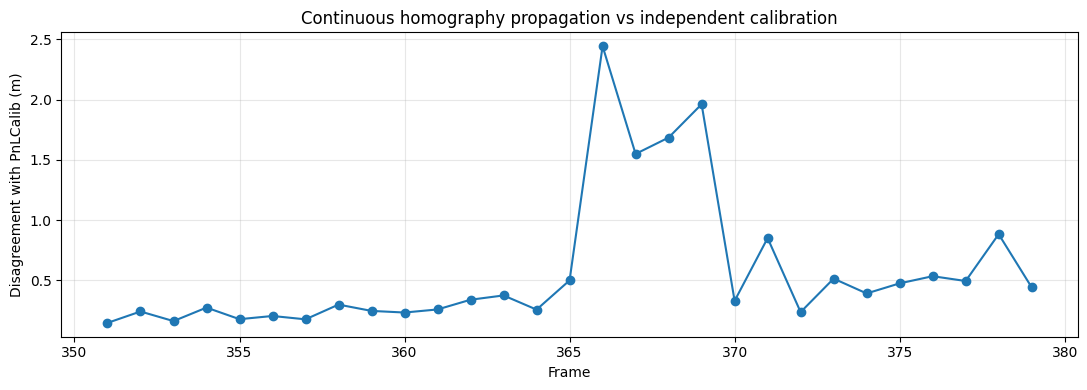

In [24]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

SEQUENCE = "SNMOT-066"
START_FRAME = 350
END_FRAME = 379

# Reuse the functions defined in Cell 33:
# load_image(), load_h(), estimate_motion_with_tracks(), transform()

H_anchor = load_h(START_FRAME)
H_propagated = H_anchor.copy()

records = []

print("PNLCALIB — LONG-TERM PROPAGATION DRIFT")
print("=" * 72)

for f1 in range(START_FRAME, END_FRAME):

    f2 = f1 + 1

    img1 = load_image(f1)
    img2 = load_image(f2)

    motion = estimate_motion_with_tracks(img1, img2)

    if motion is None:
        print(f"{f1}->{f2}: propagation unavailable")
        break

    M, test_p1, test_p2, inlier_ratio = motion

    if not np.isfinite(M).all() or np.linalg.matrix_rank(M) < 3:
        print(f"{f1}->{f2}: invalid camera-motion matrix")
        break

    # Propagate from the previous propagated estimate,
    # rather than resetting to PnLCalib every frame.
    H_propagated = H_propagated @ np.linalg.inv(M)

    H_direct = load_h(f2)

    height, width = img2.shape[:2]

    grid = np.array([
        [x, y]
        for y in np.linspace(100, height - 100, 8)
        for x in np.linspace(100, width - 100, 12)
    ], dtype=np.float64)

    pitch_direct = transform(grid, H_direct)
    pitch_prop = transform(grid, H_propagated)

    valid = (
        np.isfinite(pitch_direct).all(axis=1)
        & np.isfinite(pitch_prop).all(axis=1)
    )

    for pts in (pitch_direct, pitch_prop):
        valid &= (
            (pts[:, 0] >= 0) & (pts[:, 0] <= 105)
            & (pts[:, 1] >= 0) & (pts[:, 1] <= 68)
        )

    if valid.sum() < 10:
        print(f"{f2}: insufficient common pitch coverage")
        continue

    disagreement = np.linalg.norm(
        pitch_direct[valid] - pitch_prop[valid],
        axis=1
    )

    record = {
        "frame": f2,
        "frames_since_anchor": f2 - START_FRAME,
        "median_disagreement_m": float(np.median(disagreement)),
        "p90_disagreement_m": float(np.percentile(disagreement, 90)),
        "inlier_ratio": float(inlier_ratio)
    }

    records.append(record)

    print(
        f"Frame {f2} | "
        f"since anchor={f2 - START_FRAME:2d} | "
        f"disagreement={record['median_disagreement_m']:.3f} m | "
        f"inliers={inlier_ratio:.1%}"
    )

print("\n" + "=" * 72)
print("DRIFT TEST SUMMARY")
print("=" * 72)

if records:

    values = np.array([
        r["median_disagreement_m"]
        for r in records
    ])

    print("Frames evaluated:", len(records))
    print("Median disagreement:", round(float(np.median(values)), 3), "m")
    print("Maximum disagreement:", round(float(np.max(values)), 3), "m")
    print("Final evaluated disagreement:", round(float(values[-1]), 3), "m")

    plt.figure(figsize=(11, 4))

    plt.plot(
        [r["frame"] for r in records],
        values,
        marker="o"
    )

    plt.xlabel("Frame")
    plt.ylabel("Disagreement with PnLCalib (m)")
    plt.title("Continuous homography propagation vs independent calibration")
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

else:
    print("No frames evaluated.")

In [25]:
import numpy as np
import cv2
from pathlib import Path
import json

# --------------------------------------------------
# 1. Configuration
# --------------------------------------------------

SEQUENCE = "SNMOT-066"
START_FRAME = 350
END_FRAME = 379

OUTPUT_DIR = (
    Path("/content/drive/MyDrive/Football_CV_Project")
    / "outputs/calibration/v2.0"
    / "hybrid_test"
)

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Initial experimental thresholds.
# These are NOT validated universal values.
MIN_INLIER_RATIO = 0.75
MAX_DISAGREEMENT_M = 0.75

# --------------------------------------------------
# 2. Helper: Compare homographies in pitch space
# --------------------------------------------------

def homography_disagreement(H_a, H_b, image_shape):

    height, width = image_shape[:2]

    points = np.array([
        [x, y]
        for y in np.linspace(100, height - 100, 8)
        for x in np.linspace(100, width - 100, 12)
    ], dtype=np.float64)

    pitch_a = transform(points, H_a)
    pitch_b = transform(points, H_b)

    valid = (
        np.isfinite(pitch_a).all(axis=1)
        & np.isfinite(pitch_b).all(axis=1)
    )

    for pts in (pitch_a, pitch_b):
        valid &= (
            (pts[:, 0] >= 0)
            & (pts[:, 0] <= 105)
            & (pts[:, 1] >= 0)
            & (pts[:, 1] <= 68)
        )

    if valid.sum() < 10:
        return None

    differences = np.linalg.norm(
        pitch_a[valid] - pitch_b[valid],
        axis=1
    )

    return float(np.median(differences))


# --------------------------------------------------
# 3. Initialize hybrid calibration
# --------------------------------------------------

H_hybrid = load_h(START_FRAME)

records = []

first_record = {
    "frame": START_FRAME,
    "method": "initial_pnlcalib",
    "disagreement_m": 0.0,
    "inlier_ratio": None
}

records.append(first_record)

np.savez_compressed(
    OUTPUT_DIR / f"{SEQUENCE}_{START_FRAME:06d}.npz",
    H_image_to_pitch=H_hybrid,
    method="initial_pnlcalib"
)

print("HYBRID CAMERA CALIBRATION")
print("=" * 78)
print(f"Frame {START_FRAME}: initial PnLCalib anchor")

# --------------------------------------------------
# 4. Process consecutive frames
# --------------------------------------------------

for f1 in range(START_FRAME, END_FRAME):

    f2 = f1 + 1

    img1 = load_image(f1)
    img2 = load_image(f2)

    H_direct = load_h(f2)

    motion = estimate_motion_with_tracks(img1, img2)

    method = None
    disagreement = None
    inlier_ratio = None

    if motion is None:

        # No reliable motion estimate.
        H_hybrid = H_direct.copy()
        method = "pnlcalib_fallback"

    else:

        M, _, _, inlier_ratio = motion

        if (
            inlier_ratio < MIN_INLIER_RATIO
            or not np.isfinite(M).all()
            or np.linalg.matrix_rank(M) < 3
        ):

            H_hybrid = H_direct.copy()
            method = "pnlcalib_fallback"

        else:

            # Propagate previous accepted calibration.
            H_propagated = H_hybrid @ np.linalg.inv(M)

            disagreement = homography_disagreement(
                H_direct,
                H_propagated,
                img2.shape
            )

            if disagreement is None:

                H_hybrid = H_direct.copy()
                method = "pnlcalib_fallback"

            elif disagreement <= MAX_DISAGREEMENT_M:

                # Direct estimate agrees with camera motion.
                H_hybrid = H_direct.copy()
                method = "pnlcalib_anchor"

            else:

                # Reject suspicious independent jump.
                H_hybrid = H_propagated.copy()
                method = "motion_propagated"

    # --------------------------------------------------
    # 5. Save hybrid homography
    # --------------------------------------------------

    np.savez_compressed(
        OUTPUT_DIR / f"{SEQUENCE}_{f2:06d}.npz",
        H_image_to_pitch=H_hybrid,
        method=method,
        frame_number=f2
    )

    records.append({
        "frame": f2,
        "method": method,
        "disagreement_m": disagreement,
        "inlier_ratio": (
            float(inlier_ratio)
            if inlier_ratio is not None
            else None
        )
    })

    disagreement_text = (
        f"{disagreement:.3f}m"
        if disagreement is not None
        else "N/A"
    )

    print(
        f"Frame {f2} | "
        f"method={method:20s} | "
        f"disagreement={disagreement_text}"
    )

# --------------------------------------------------
# 6. Save summary
# --------------------------------------------------

manifest_path = OUTPUT_DIR / "hybrid_manifest.json"

with open(manifest_path, "w") as f:
    json.dump(records, f, indent=2)

methods = [r["method"] for r in records]

print("\n" + "=" * 78)
print("HYBRID CALIBRATION SUMMARY")
print("=" * 78)

print("Frames processed:", len(records))
print("PnLCalib anchors:", methods.count("pnlcalib_anchor"))
print("Motion-propagated:", methods.count("motion_propagated"))
print("PnLCalib fallbacks:", methods.count("pnlcalib_fallback"))
print("Initial anchor:", methods.count("initial_pnlcalib"))
print("Manifest saved:", manifest_path)

HYBRID CAMERA CALIBRATION
Frame 350: initial PnLCalib anchor
Frame 351 | method=pnlcalib_anchor      | disagreement=0.148m
Frame 352 | method=pnlcalib_anchor      | disagreement=0.351m
Frame 353 | method=pnlcalib_anchor      | disagreement=0.358m
Frame 354 | method=pnlcalib_anchor      | disagreement=0.289m
Frame 355 | method=pnlcalib_anchor      | disagreement=0.227m
Frame 356 | method=pnlcalib_anchor      | disagreement=0.254m
Frame 357 | method=pnlcalib_anchor      | disagreement=0.319m
Frame 358 | method=pnlcalib_anchor      | disagreement=0.185m
Frame 359 | method=pnlcalib_anchor      | disagreement=0.117m
Frame 360 | method=pnlcalib_anchor      | disagreement=0.206m
Frame 361 | method=pnlcalib_anchor      | disagreement=0.229m
Frame 362 | method=pnlcalib_anchor      | disagreement=0.156m
Frame 363 | method=pnlcalib_anchor      | disagreement=0.336m
Frame 364 | method=pnlcalib_anchor      | disagreement=0.317m
Frame 365 | method=pnlcalib_anchor      | disagreement=0.543m
Frame 366

In [26]:
import numpy as np
import cv2
from pathlib import Path

PROJECT_ROOT = Path("/content/drive/MyDrive/Football_CV_Project")

HYBRID_DIR = (
    PROJECT_ROOT
    / "outputs/calibration/v2.0/hybrid_test"
)

SEQUENCE = "SNMOT-066"
START_FRAME = 350
END_FRAME = 379

def load_hybrid(frame_number):
    path = HYBRID_DIR / f"{SEQUENCE}_{frame_number:06d}.npz"
    with np.load(path) as data:
        return data["H_image_to_pitch"].astype(np.float64)

def stationary_consistency(p1, p2, H1, H2):
    pitch1 = transform(p1, H1)
    pitch2 = transform(p2, H2)

    valid = (
        np.isfinite(pitch1).all(axis=1)
        & np.isfinite(pitch2).all(axis=1)
    )

    for pts in (pitch1, pitch2):
        valid &= (
            (pts[:, 0] >= 0)
            & (pts[:, 0] <= 105)
            & (pts[:, 1] >= 0)
            & (pts[:, 1] <= 68)
        )

    if valid.sum() < 10:
        return np.nan

    distances = np.linalg.norm(
        pitch2[valid] - pitch1[valid],
        axis=1
    )

    return float(np.median(distances))

# Start continuous propagation at the same anchor.
H_continuous = load_h(START_FRAME)

results = []

print("THREE-WAY TEMPORAL CALIBRATION COMPARISON")
print("=" * 85)

for f1 in range(START_FRAME, END_FRAME):

    f2 = f1 + 1

    img1 = load_image(f1)
    img2 = load_image(f2)

    motion = estimate_motion_with_tracks(img1, img2)

    if motion is None:
        print(f"{f1}->{f2}: skipped — insufficient tracks")
        continue

    M, p1_test, p2_test, inlier_ratio = motion

    if (
        not np.isfinite(M).all()
        or np.linalg.matrix_rank(M) < 3
    ):
        print(f"{f1}->{f2}: skipped — invalid motion")
        continue

    H_previous_continuous = H_continuous.copy()
    H_continuous = H_continuous @ np.linalg.inv(M)

    direct_error = stationary_consistency(
        p1_test,
        p2_test,
        load_h(f1),
        load_h(f2)
    )

    propagated_error = stationary_consistency(
        p1_test,
        p2_test,
        H_previous_continuous,
        H_continuous
    )

    hybrid_error = stationary_consistency(
        p1_test,
        p2_test,
        load_hybrid(f1),
        load_hybrid(f2)
    )

    results.append({
        "frame1": f1,
        "frame2": f2,
        "direct": direct_error,
        "propagated": propagated_error,
        "hybrid": hybrid_error
    })

    print(
        f"{f1}->{f2} | "
        f"Direct={direct_error:.3f}m | "
        f"Propagated={propagated_error:.3f}m | "
        f"Hybrid={hybrid_error:.3f}m"
    )

print("\n" + "=" * 85)
print("COMPARISON SUMMARY")
print("=" * 85)

for method in ("direct", "propagated", "hybrid"):

    values = np.array(
        [r[method] for r in results],
        dtype=float
    )

    finite = values[np.isfinite(values)]

    if len(finite) == 0:
        print(f"{method}: no valid measurements")
        continue

    print(
        f"{method.upper():12s} | "
        f"median={np.median(finite):.3f}m | "
        f"worst={np.max(finite):.3f}m | "
        f"valid_pairs={len(finite)}"
    )

print("\nThese are temporal consistency measurements, not absolute accuracy.")

THREE-WAY TEMPORAL CALIBRATION COMPARISON
350->351 | Direct=0.166m | Propagated=0.197m | Hybrid=0.166m
351->352 | Direct=0.379m | Propagated=0.178m | Hybrid=0.379m
352->353 | Direct=0.274m | Propagated=0.174m | Hybrid=0.274m
353->354 | Direct=0.253m | Propagated=0.140m | Hybrid=0.253m
354->355 | Direct=0.286m | Propagated=0.150m | Hybrid=0.286m
355->356 | Direct=0.329m | Propagated=0.188m | Hybrid=0.329m
356->357 | Direct=0.239m | Propagated=0.202m | Hybrid=0.239m
357->358 | Direct=0.276m | Propagated=0.191m | Hybrid=0.276m
358->359 | Direct=0.233m | Propagated=0.199m | Hybrid=0.233m
359->360 | Direct=0.207m | Propagated=0.153m | Hybrid=0.207m
360->361 | Direct=0.250m | Propagated=0.173m | Hybrid=0.250m
361->362 | Direct=0.244m | Propagated=0.182m | Hybrid=0.244m
362->363 | Direct=0.358m | Propagated=0.239m | Hybrid=0.358m
363->364 | Direct=0.369m | Propagated=0.223m | Hybrid=0.369m
364->365 | Direct=0.336m | Propagated=0.241m | Hybrid=0.336m
365->366 | Direct=1.193m | Propagated=0.230

In [27]:
from pathlib import Path

PROJECT_ROOT = Path("/content/drive/MyDrive/Football_CV_Project")
DATA_ROOT = PROJECT_ROOT / "data/raw/soccernet"

test_sequences = {
    "SNMOT-060": range(350, 380),
    "SNMOT-069": range(350, 380)
}

print("CROSS-SEQUENCE GENERALIZATION — DATA CHECK")
print("=" * 65)

all_available = True

for sequence, frame_numbers in test_sequences.items():

    missing = []

    for frame_number in frame_numbers:

        image_path = (
            DATA_ROOT
            / sequence
            / "img1"
            / f"{frame_number:06d}.jpg"
        )

        if not image_path.exists():
            missing.append(frame_number)

    available = len(frame_numbers) - len(missing)

    print(f"\nSequence: {sequence}")
    print("Frames requested:", len(frame_numbers))
    print("Frames available:", available)
    print("Missing:", len(missing))

    if missing:
        print("Missing frame numbers:", missing)
        all_available = False

print("\n" + "=" * 65)

if all_available:
    print("STATUS: READY FOR CROSS-SEQUENCE TESTING")
else:
    print("STATUS: MISSING FRAMES — REVIEW REQUIRED")

CROSS-SEQUENCE GENERALIZATION — DATA CHECK

Sequence: SNMOT-060
Frames requested: 30
Frames available: 30
Missing: 0

Sequence: SNMOT-069
Frames requested: 30
Frames available: 30
Missing: 0

STATUS: READY FOR CROSS-SEQUENCE TESTING


In [28]:
import time
import json
import numpy as np
from pathlib import Path

# --------------------------------------------------
# 1. Verify project and model state
# --------------------------------------------------

PROJECT_ROOT = Path("/content/drive/MyDrive/Football_CV_Project")
DATA_ROOT = PROJECT_ROOT / "data/raw/soccernet"

CROSS_DIR = (
    PROJECT_ROOT
    / "outputs/calibration/v2.0"
    / "cross_sequence_test"
)

CROSS_DIR.mkdir(parents=True, exist_ok=True)

assert DATA_ROOT.exists(), "SoccerNet data directory not found."
assert callable(calibrate_frame), (
    "calibrate_frame() is unavailable. "
    "Run Cell 25 to reload the models."
)

test_sequences = {
    "SNMOT-060": range(350, 380),
    "SNMOT-069": range(350, 380)
}

# --------------------------------------------------
# 2. Run calibration
# --------------------------------------------------

records = []
start_time = time.time()

print("PNLCALIB — CROSS-SEQUENCE CALIBRATION")
print("=" * 72)

for sequence, frame_numbers in test_sequences.items():

    sequence_dir = CROSS_DIR / sequence
    sequence_dir.mkdir(parents=True, exist_ok=True)

    print(f"\nSequence: {sequence}")
    print("-" * 50)

    for frame_number in frame_numbers:

        image_path = (
            DATA_ROOT
            / sequence
            / "img1"
            / f"{frame_number:06d}.jpg"
        )

        record = {
            "sequence": sequence,
            "frame": frame_number,
            "status": "failed"
        }

        try:
            params, H_p2i, H_i2p, frame = calibrate_frame(
                image_path
            )

            if params is None:
                record["reason"] = "No camera estimate"

            else:
                if not (
                    np.isfinite(H_p2i).all()
                    and np.isfinite(H_i2p).all()
                ):
                    raise ValueError("Non-finite homography")

                if np.linalg.matrix_rank(H_i2p) < 3:
                    raise ValueError("Singular homography")

                save_path = (
                    sequence_dir
                    / f"{sequence}_{frame_number:06d}.npz"
                )

                np.savez_compressed(
                    save_path,
                    H_pitch_to_image=H_p2i,
                    H_image_to_pitch=H_i2p,
                    projection_matrix=(
                        pnl.projection_from_cam_params(params)
                    ),
                    sequence=sequence,
                    frame_number=frame_number,
                    pitch_length=105.0,
                    pitch_width=68.0
                )

                record["status"] = "exported"
                record["file"] = str(save_path)

        except Exception as e:
            record["reason"] = str(e)

        records.append(record)

        print(
            f"Frame {frame_number}: {record['status']}"
        )

# --------------------------------------------------
# 3. Save manifest and summarize
# --------------------------------------------------

manifest_path = CROSS_DIR / "cross_sequence_manifest.json"

with open(manifest_path, "w") as f:
    json.dump(records, f, indent=2)

elapsed = time.time() - start_time

print("\n" + "=" * 72)
print("CROSS-SEQUENCE EXPORT SUMMARY")
print("=" * 72)

for sequence in test_sequences:

    subset = [
        r for r in records
        if r["sequence"] == sequence
    ]

    successful = sum(
        r["status"] == "exported"
        for r in subset
    )

    print(
        f"{sequence}: "
        f"{successful}/{len(subset)} exported"
    )

total_successful = sum(
    r["status"] == "exported"
    for r in records
)

print("\nTotal:", total_successful, "/", len(records))
print("Elapsed:", round(elapsed, 2), "seconds")
print("Average:", round(elapsed / len(records), 2), "seconds/frame")
print("Manifest:", manifest_path)

print("\nCell 38 completed.")

PNLCALIB — CROSS-SEQUENCE CALIBRATION

Sequence: SNMOT-060
--------------------------------------------------
Frame 350: exported
Frame 351: exported
Frame 352: exported
Frame 353: exported
Frame 354: exported
Frame 355: exported
Frame 356: exported
Frame 357: exported
Frame 358: exported
Frame 359: exported
Frame 360: exported
Frame 361: exported
Frame 362: exported
Frame 363: exported
Frame 364: exported
Frame 365: exported
Frame 366: exported
Frame 367: exported
Frame 368: exported
Frame 369: exported
Frame 370: exported
Frame 371: exported
Frame 372: exported
Frame 373: exported
Frame 374: exported
Frame 375: exported
Frame 376: exported
Frame 377: exported
Frame 378: exported
Frame 379: exported

Sequence: SNMOT-069
--------------------------------------------------
Frame 350: exported
Frame 351: exported
Frame 352: exported
Frame 353: exported
Frame 354: exported
Frame 355: exported
Frame 356: exported
Frame 357: exported
Frame 358: exported
Frame 359: exported
Frame 360: exporte

In [29]:
import numpy as np
import cv2
import json
from pathlib import Path

PROJECT_ROOT = Path("/content/drive/MyDrive/Football_CV_Project")
DATA_ROOT = PROJECT_ROOT / "data/raw/soccernet"

CROSS_DIR = PROJECT_ROOT / "outputs/calibration/v2.0/cross_sequence_test"
HYBRID_CROSS_DIR = CROSS_DIR / "hybrid"
HYBRID_CROSS_DIR.mkdir(parents=True, exist_ok=True)

# Same experimental settings as Cell 35 — no retuning.
MIN_INLIER_RATIO = 0.75
MAX_DISAGREEMENT_M = 0.75

sequences = ["SNMOT-060", "SNMOT-069"]
start_frame, end_frame = 350, 379

def cross_image(sequence, frame_number):
    path = DATA_ROOT / sequence / "img1" / f"{frame_number:06d}.jpg"
    image = cv2.imread(str(path))
    if image is None:
        raise FileNotFoundError(path)
    return image

def cross_direct_h(sequence, frame_number):
    path = CROSS_DIR / sequence / f"{sequence}_{frame_number:06d}.npz"
    with np.load(path) as data:
        return data["H_image_to_pitch"].astype(np.float64)

def save_cross_hybrid(sequence, frame_number, H, method):
    folder = HYBRID_CROSS_DIR / sequence
    folder.mkdir(parents=True, exist_ok=True)

    np.savez_compressed(
        folder / f"{sequence}_{frame_number:06d}.npz",
        H_image_to_pitch=H,
        method=method,
        sequence=sequence,
        frame_number=frame_number
    )

def safe_motion_inverse(M):
    if M is None or not np.isfinite(M).all():
        return None
    if np.linalg.matrix_rank(M) < 3:
        return None
    try:
        inverse = np.linalg.inv(M)
        if not np.isfinite(inverse).all():
            return None
        return inverse
    except np.linalg.LinAlgError:
        return None

all_results = {}

print("CROSS-SEQUENCE HYBRID GENERALIZATION TEST")
print("=" * 82)

for sequence in sequences:

    print(f"\nSEQUENCE: {sequence}")
    print("-" * 82)

    H_hybrid = cross_direct_h(sequence, start_frame)
    H_continuous = H_hybrid.copy()

    save_cross_hybrid(
        sequence, start_frame, H_hybrid, "initial_pnlcalib"
    )

    records = []
    method_counts = {
        "pnlcalib_anchor": 0,
        "motion_propagated": 0,
        "pnlcalib_fallback": 0
    }

    for f1 in range(start_frame, end_frame):

        f2 = f1 + 1

        img1 = cross_image(sequence, f1)
        img2 = cross_image(sequence, f2)

        H_direct_1 = cross_direct_h(sequence, f1)
        H_direct_2 = cross_direct_h(sequence, f2)

        H_hybrid_previous = H_hybrid.copy()
        H_continuous_previous = H_continuous.copy()

        motion = estimate_motion_with_tracks(img1, img2)

        inlier_ratio = None
        disagreement = None
        direct_error = np.nan
        continuous_error = np.nan
        hybrid_error = np.nan

        inverse_M = None
        p1_test = None
        p2_test = None

        if motion is not None:
            M, p1_test, p2_test, inlier_ratio = motion
            inverse_M = safe_motion_inverse(M)

        if inverse_M is None:
            H_hybrid = H_direct_2.copy()
            method = "pnlcalib_fallback"

        else:
            H_continuous = H_continuous @ inverse_M

            if inlier_ratio < MIN_INLIER_RATIO:
                H_hybrid = H_direct_2.copy()
                method = "pnlcalib_fallback"

            else:
                H_candidate = H_hybrid @ inverse_M

                disagreement = homography_disagreement(
                    H_direct_2, H_candidate, img2.shape
                )

                if disagreement is None:
                    H_hybrid = H_direct_2.copy()
                    method = "pnlcalib_fallback"

                elif disagreement <= MAX_DISAGREEMENT_M:
                    H_hybrid = H_direct_2.copy()
                    method = "pnlcalib_anchor"

                else:
                    H_hybrid = H_candidate.copy()
                    method = "motion_propagated"

            # Held-out feature tracks from the motion estimator.
            direct_error = stationary_consistency(
                p1_test, p2_test, H_direct_1, H_direct_2
            )

            continuous_error = stationary_consistency(
                p1_test, p2_test,
                H_continuous_previous, H_continuous
            )

            hybrid_error = stationary_consistency(
                p1_test, p2_test,
                H_hybrid_previous, H_hybrid
            )

        save_cross_hybrid(sequence, f2, H_hybrid, method)
        method_counts[method] += 1

        records.append({
            "frame1": f1,
            "frame2": f2,
            "method": method,
            "inlier_ratio": (
                float(inlier_ratio)
                if inlier_ratio is not None else None
            ),
            "disagreement_m": disagreement,
            "direct_m": float(direct_error),
            "continuous_m": float(continuous_error),
            "hybrid_m": float(hybrid_error)
        })

        print(
            f"{f1}->{f2} | {method:19s} | "
            f"Direct={direct_error:.3f}m | "
            f"Flow={continuous_error:.3f}m | "
            f"Hybrid={hybrid_error:.3f}m"
        )

    def summarize(key):
        values = np.array(
            [r[key] for r in records], dtype=float
        )
        valid = values[np.isfinite(values)]

        if len(valid) == 0:
            return {"median": None, "worst": None, "count": 0}

        return {
            "median": float(np.median(valid)),
            "worst": float(np.max(valid)),
            "count": int(len(valid))
        }

    summary = {
        "sequence": sequence,
        "direct": summarize("direct_m"),
        "continuous": summarize("continuous_m"),
        "hybrid": summarize("hybrid_m"),
        "method_counts": method_counts,
        "records": records
    }

    all_results[sequence] = summary

    print("\nSUMMARY:", sequence)

    for label in ("direct", "continuous", "hybrid"):
        stats = summary[label]
        print(
            f"  {label:12s} "
            f"median={stats['median']} | "
            f"worst={stats['worst']} | "
            f"valid_pairs={stats['count']}"
        )

    print("  Method counts:", method_counts)

output_path = HYBRID_CROSS_DIR / "generalization_results.json"

with open(output_path, "w") as file:
    json.dump(all_results, file, indent=2, allow_nan=False)

print("\n" + "=" * 82)
print("CROSS-SEQUENCE TEST COMPLETE")
print("Results saved:", output_path)
print("Hybrid homographies saved:", HYBRID_CROSS_DIR)

CROSS-SEQUENCE HYBRID GENERALIZATION TEST

SEQUENCE: SNMOT-060
----------------------------------------------------------------------------------
350->351 | pnlcalib_anchor     | Direct=0.153m | Flow=0.167m | Hybrid=0.153m
351->352 | pnlcalib_anchor     | Direct=0.173m | Flow=0.139m | Hybrid=0.173m
352->353 | pnlcalib_anchor     | Direct=0.176m | Flow=0.140m | Hybrid=0.176m
353->354 | pnlcalib_anchor     | Direct=0.166m | Flow=0.151m | Hybrid=0.166m
354->355 | pnlcalib_anchor     | Direct=0.154m | Flow=0.079m | Hybrid=0.154m
355->356 | pnlcalib_anchor     | Direct=0.203m | Flow=0.072m | Hybrid=0.203m
356->357 | motion_propagated   | Direct=0.610m | Flow=0.102m | Hybrid=0.101m
357->358 | pnlcalib_anchor     | Direct=0.361m | Flow=0.100m | Hybrid=0.277m
358->359 | pnlcalib_anchor     | Direct=0.093m | Flow=0.109m | Hybrid=0.093m
359->360 | pnlcalib_anchor     | Direct=0.193m | Flow=0.129m | Hybrid=0.193m
360->361 | pnlcalib_anchor     | Direct=0.326m | Flow=0.172m | Hybrid=0.326m
361->36

In [30]:
import json
import numpy as np
from pathlib import Path

PROJECT_ROOT = Path("/content/drive/MyDrive/Football_CV_Project")

RESULTS_PATH = (
    PROJECT_ROOT
    / "outputs/calibration/v2.0"
    / "cross_sequence_test/hybrid/generalization_results.json"
)

with open(RESULTS_PATH, "r") as f:
    results = json.load(f)

print("HYBRID CALIBRATION — THRESHOLD DIAGNOSTICS")
print("=" * 80)

for sequence, data in results.items():

    records = data["records"]

    disagreements = np.array([
        r["disagreement_m"]
        for r in records
        if r["disagreement_m"] is not None
    ], dtype=float)

    print(f"\nSequence: {sequence}")
    print("-" * 60)

    print("Median disagreement:",
          round(float(np.median(disagreements)), 3), "m")

    print("75th percentile:",
          round(float(np.percentile(disagreements, 75)), 3), "m")

    print("90th percentile:",
          round(float(np.percentile(disagreements, 90)), 3), "m")

    print("Maximum disagreement:",
          round(float(np.max(disagreements)), 3), "m")

    print("\nLargest disagreements:")

    sorted_records = sorted(
        [
            r for r in records
            if r["disagreement_m"] is not None
        ],
        key=lambda r: r["disagreement_m"],
        reverse=True
    )

    for record in sorted_records[:5]:
        print(
            f"  {record['frame1']}->{record['frame2']} | "
            f"{record['disagreement_m']:.3f}m | "
            f"{record['method']}"
        )

print("\nReference threshold used in Cell 39: 0.75 m")

HYBRID CALIBRATION — THRESHOLD DIAGNOSTICS

Sequence: SNMOT-060
------------------------------------------------------------
Median disagreement: 0.182 m
75th percentile: 0.298 m
90th percentile: 0.339 m
Maximum disagreement: 0.81 m

Largest disagreements:
  356->357 | 0.810m | motion_propagated
  363->364 | 0.699m | pnlcalib_anchor
  362->363 | 0.357m | pnlcalib_anchor
  360->361 | 0.335m | pnlcalib_anchor
  361->362 | 0.333m | pnlcalib_anchor

Sequence: SNMOT-069
------------------------------------------------------------
Median disagreement: 0.165 m
75th percentile: 0.198 m
90th percentile: 0.293 m
Maximum disagreement: 0.377 m

Largest disagreements:
  376->377 | 0.377m | pnlcalib_anchor
  375->376 | 0.361m | pnlcalib_anchor
  378->379 | 0.355m | pnlcalib_anchor
  350->351 | 0.278m | pnlcalib_anchor
  355->356 | 0.244m | pnlcalib_anchor

Reference threshold used in Cell 39: 0.75 m


In [31]:
import numpy as np
import json
from pathlib import Path

PROJECT_ROOT = Path("/content/drive/MyDrive/Football_CV_Project")

ADAPTIVE_DIR = (
    PROJECT_ROOT
    / "outputs/calibration/v2.0"
    / "adaptive_hybrid_test"
)

ADAPTIVE_DIR.mkdir(parents=True, exist_ok=True)

SEQUENCES = ["SNMOT-060", "SNMOT-069"]

START_FRAME = 350
END_FRAME = 379

# Experimental settings, not independently validated.
HISTORY_SIZE = 10
MIN_HISTORY = 5
ADAPTIVE_MULTIPLIER = 2.5
MIN_THRESHOLD_M = 0.25
MAX_THRESHOLD_M = 0.75
MAX_PROPAGATION_FRAMES = 10
MIN_INLIER_RATIO = 0.75

all_adaptive_results = {}

print("ADAPTIVE HYBRID CALIBRATION")
print("=" * 85)

for sequence in SEQUENCES:

    H_hybrid = cross_direct_h(sequence, START_FRAME)

    history = []
    propagation_count = 0
    records = []

    sequence_dir = ADAPTIVE_DIR / sequence
    sequence_dir.mkdir(parents=True, exist_ok=True)

    np.savez_compressed(
        sequence_dir / f"{sequence}_{START_FRAME:06d}.npz",
        H_image_to_pitch=H_hybrid,
        method="initial_pnlcalib"
    )

    print(f"\nSEQUENCE: {sequence}")
    print("-" * 85)

    for f1 in range(START_FRAME, END_FRAME):

        f2 = f1 + 1

        img1 = cross_image(sequence, f1)
        img2 = cross_image(sequence, f2)

        H_direct = cross_direct_h(sequence, f2)
        H_previous = H_hybrid.copy()

        motion = estimate_motion_with_tracks(img1, img2)

        disagreement = None
        threshold = None
        inlier_ratio = None

        if motion is None:
            H_hybrid = H_direct.copy()
            method = "pnlcalib_fallback"
            propagation_count = 0

        else:
            M, p1_test, p2_test, inlier_ratio = motion
            inverse_M = safe_motion_inverse(M)

            if (
                inverse_M is None
                or inlier_ratio < MIN_INLIER_RATIO
            ):
                H_hybrid = H_direct.copy()
                method = "pnlcalib_fallback"
                propagation_count = 0

            else:
                H_predicted = H_previous @ inverse_M

                disagreement = homography_disagreement(
                    H_direct,
                    H_predicted,
                    img2.shape
                )

                if disagreement is None:
                    H_hybrid = H_direct.copy()
                    method = "pnlcalib_fallback"
                    propagation_count = 0

                else:
                    if len(history) >= MIN_HISTORY:
                        recent = np.array(
                            history[-HISTORY_SIZE:],
                            dtype=float
                        )

                        typical = float(np.median(recent))

                        threshold = float(np.clip(
                            typical * ADAPTIVE_MULTIPLIER,
                            MIN_THRESHOLD_M,
                            MAX_THRESHOLD_M
                        ))
                    else:
                        threshold = MAX_THRESHOLD_M

                    unusual_jump = disagreement > threshold

                    if (
                        unusual_jump
                        and propagation_count < MAX_PROPAGATION_FRAMES
                    ):
                        H_hybrid = H_predicted.copy()
                        method = "motion_propagated"
                        propagation_count += 1

                    else:
                        H_hybrid = H_direct.copy()
                        method = "pnlcalib_anchor"
                        propagation_count = 0

                    # Learn the baseline only from accepted
                    # estimates, not rejected outliers.
                    if method == "pnlcalib_anchor":
                        history.append(disagreement)

        np.savez_compressed(
            sequence_dir / f"{sequence}_{f2:06d}.npz",
            H_image_to_pitch=H_hybrid,
            method=method,
            frame_number=f2
        )

        if motion is not None and inverse_M is not None:
            adaptive_error = stationary_consistency(
                p1_test,
                p2_test,
                H_previous,
                H_hybrid
            )
        else:
            adaptive_error = np.nan

        records.append({
            "frame": f2,
            "method": method,
            "disagreement_m": disagreement,
            "threshold_m": threshold,
            "temporal_error_m": (
                float(adaptive_error)
                if np.isfinite(adaptive_error)
                else None
            )
        })

        d_text = (
            f"{disagreement:.3f}"
            if disagreement is not None else "N/A"
        )

        t_text = (
            f"{threshold:.3f}"
            if threshold is not None else "N/A"
        )

        e_text = (
            f"{adaptive_error:.3f}"
            if np.isfinite(adaptive_error) else "N/A"
        )

        print(
            f"{f1}->{f2} | "
            f"{method:19s} | "
            f"disagreement={d_text}m | "
            f"threshold={t_text}m | "
            f"temporal={e_text}m"
        )

    valid_errors = np.array([
        r["temporal_error_m"]
        for r in records
        if r["temporal_error_m"] is not None
    ])

    counts = {
        method: sum(r["method"] == method for r in records)
        for method in (
            "pnlcalib_anchor",
            "motion_propagated",
            "pnlcalib_fallback"
        )
    }

    summary = {
        "sequence": sequence,
        "median_temporal_error_m": (
            float(np.median(valid_errors))
            if len(valid_errors) else None
        ),
        "worst_temporal_error_m": (
            float(np.max(valid_errors))
            if len(valid_errors) else None
        ),
        "method_counts": counts,
        "records": records
    }

    all_adaptive_results[sequence] = summary

    print(f"\nSUMMARY — {sequence}")
    print("Median temporal error:",
          summary["median_temporal_error_m"])
    print("Worst temporal error:",
          summary["worst_temporal_error_m"])
    print("Method counts:", counts)

output_path = ADAPTIVE_DIR / "adaptive_results.json"

with open(output_path, "w") as f:
    json.dump(all_adaptive_results, f, indent=2)

print("\nResults saved to:", output_path)

ADAPTIVE HYBRID CALIBRATION

SEQUENCE: SNMOT-060
-------------------------------------------------------------------------------------
350->351 | pnlcalib_anchor     | disagreement=0.028m | threshold=0.750m | temporal=0.153m
351->352 | pnlcalib_anchor     | disagreement=0.108m | threshold=0.750m | temporal=0.173m
352->353 | pnlcalib_anchor     | disagreement=0.152m | threshold=0.750m | temporal=0.176m
353->354 | pnlcalib_anchor     | disagreement=0.047m | threshold=0.750m | temporal=0.166m
354->355 | pnlcalib_anchor     | disagreement=0.096m | threshold=0.750m | temporal=0.154m
355->356 | motion_propagated   | disagreement=0.261m | threshold=0.250m | temporal=0.071m
356->357 | motion_propagated   | disagreement=0.554m | threshold=0.250m | temporal=0.102m
357->358 | pnlcalib_anchor     | disagreement=0.143m | threshold=0.250m | temporal=0.195m
358->359 | pnlcalib_anchor     | disagreement=0.101m | threshold=0.254m | temporal=0.093m
359->360 | pnlcalib_anchor     | disagreement=0.197m | 

In [33]:
import numpy as np

SEQUENCE = "SNMOT-069"
START_FRAME = 350
END_FRAME = 379

def load_adaptive_h(sequence, frame_number):
    path = (
        ADAPTIVE_DIR
        / sequence
        / f"{sequence}_{frame_number:06d}.npz"
    )

    with np.load(path) as data:
        return data["H_image_to_pitch"].astype(np.float64)

print("TEMPORAL ANCHOR VALIDATION — SNMOT-069")
print("=" * 92)

records = []

for f1 in range(START_FRAME, END_FRAME):

    f2 = f1 + 1

    img1 = cross_image(SEQUENCE, f1)
    img2 = cross_image(SEQUENCE, f2)

    motion = estimate_motion_with_tracks(img1, img2)

    if motion is None:
        continue

    M, p1_test, p2_test, inlier_ratio = motion
    inverse_M = safe_motion_inverse(M)

    if inverse_M is None:
        continue

    H_previous = load_adaptive_h(SEQUENCE, f1)
    H_direct = cross_direct_h(SEQUENCE, f2)

    H_propagated = H_previous @ inverse_M

    direct_error = stationary_consistency(
        p1_test,
        p2_test,
        H_previous,
        H_direct
    )

    propagated_error = stationary_consistency(
        p1_test,
        p2_test,
        H_previous,
        H_propagated
    )

    difference = direct_error - propagated_error

    records.append({
        "transition": f"{f1}->{f2}",
        "direct_error": direct_error,
        "propagated_error": propagated_error,
        "difference": difference,
        "inlier_ratio": inlier_ratio
    })

    print(
        f"{f1}->{f2} | "
        f"Direct={direct_error:.3f}m | "
        f"Propagated={propagated_error:.3f}m | "
        f"Difference={difference:+.3f}m"
    )

print("\n" + "=" * 92)
print("LARGEST POTENTIAL ANCHOR PROBLEMS")
print("=" * 92)

ranked = sorted(
    [
        r for r in records
        if np.isfinite(r["difference"])
    ],
    key=lambda r: r["difference"],
    reverse=True
)

for record in ranked[:8]:
    print(
        f"{record['transition']} | "
        f"Direct={record['direct_error']:.3f}m | "
        f"Propagated={record['propagated_error']:.3f}m | "
        f"Excess={record['difference']:.3f}m"
    )

TEMPORAL ANCHOR VALIDATION — SNMOT-069
350->351 | Direct=0.413m | Propagated=0.158m | Difference=+0.255m
351->352 | Direct=0.190m | Propagated=0.138m | Difference=+0.052m
352->353 | Direct=0.411m | Propagated=0.174m | Difference=+0.237m
353->354 | Direct=0.202m | Propagated=0.130m | Difference=+0.072m
354->355 | Direct=0.249m | Propagated=0.175m | Difference=+0.074m
355->356 | Direct=0.243m | Propagated=0.144m | Difference=+0.099m
356->357 | Direct=0.159m | Propagated=0.127m | Difference=+0.032m
357->358 | Direct=0.319m | Propagated=0.160m | Difference=+0.159m
358->359 | Direct=0.212m | Propagated=0.184m | Difference=+0.028m
359->360 | Direct=0.268m | Propagated=0.162m | Difference=+0.106m
360->361 | Direct=0.145m | Propagated=0.168m | Difference=-0.023m
361->362 | Direct=0.237m | Propagated=0.192m | Difference=+0.044m
362->363 | Direct=0.293m | Propagated=0.152m | Difference=+0.141m
363->364 | Direct=0.169m | Propagated=0.126m | Difference=+0.043m
364->365 | Direct=0.217m | Propagated

In [35]:
from pathlib import Path
import numpy as np

PROJECT_ROOT = Path("/content/drive/MyDrive/Football_CV_Project")

TEMPORAL_DIR = (
    PROJECT_ROOT
    / "outputs/calibration/v2.0"
    / "pnlcalib_export/temporal_test"
)

def get_direct_calibration(sequence, frame_number):
    """
    Load the correct PnLCalib homography using
    an explicit sequence name.

    This avoids relying on the global SEQUENCE variable.
    """

    if sequence == "SNMOT-066":
        path = (
            TEMPORAL_DIR
            / f"{sequence}_{frame_number:06d}.npz"
        )
    else:
        path = (
            CROSS_DIR
            / sequence
            / f"{sequence}_{frame_number:06d}.npz"
        )

    if not path.exists():
        raise FileNotFoundError(
            f"Calibration file not found: {path}"
        )

    with np.load(path) as data:
        H = data["H_image_to_pitch"].astype(np.float64)

    return H


# Verify that all three sequences load correctly.
for sequence in ["SNMOT-060", "SNMOT-066", "SNMOT-069"]:

    H = get_direct_calibration(sequence, 350)

    print(
        f"{sequence}: "
        f"Loaded successfully | "
        f"Shape={H.shape} | "
        f"Finite={np.isfinite(H).all()}"
    )

SNMOT-060: Loaded successfully | Shape=(3, 3) | Finite=True
SNMOT-066: Loaded successfully | Shape=(3, 3) | Finite=True
SNMOT-069: Loaded successfully | Shape=(3, 3) | Finite=True


In [38]:
from pathlib import Path
import numpy as np
import json

PROJECT_ROOT = Path("/content/drive/MyDrive/Football_CV_Project")

TEMPORAL_DIR = (
    PROJECT_ROOT
    / "outputs/calibration/v2.0/pnlcalib_export/temporal_test"
)

CROSS_DIR = (
    PROJECT_ROOT
    / "outputs/calibration/v2.0/cross_sequence_test"
)

# Replace the old function.
def get_direct_calibration(sequence, frame_number):

    if sequence == "SNMOT-066":
        path = TEMPORAL_DIR / f"{sequence}_{frame_number:06d}.npz"
    else:
        path = CROSS_DIR / sequence / f"{sequence}_{frame_number:06d}.npz"

    if not path.exists():
        raise FileNotFoundError(f"Missing calibration: {path}")

    with np.load(path) as data:
        return data["H_image_to_pitch"].astype(np.float64)


# Confirm that the corrected loader works.
print("CALIBRATION FILE CHECK")
print("=" * 60)

for sequence in ["SNMOT-060", "SNMOT-066", "SNMOT-069"]:
    H = get_direct_calibration(sequence, 350)
    print(f"{sequence}: OK | shape={H.shape}")


# Run the existing dual-check function.
# Do not rerun the original Cell 43.
print("\nDUAL-CHECK HYBRID CALIBRATION")
print("=" * 60)

all_results = {}

for sequence in ["SNMOT-060", "SNMOT-066", "SNMOT-069"]:

    records = dual_check_calibration(sequence)

    counts = {
        method: sum(r["method"] == method for r in records)
        for method in (
            "pnlcalib_anchor",
            "motion_propagated",
            "pnlcalib_fallback"
        )
    }

    all_results[sequence] = {
        "method_counts": counts,
        "records": records
    }

    print(f"\n{sequence}")
    print("PnLCalib anchors:", counts["pnlcalib_anchor"])
    print("Motion propagated:", counts["motion_propagated"])
    print("Fallbacks:", counts["pnlcalib_fallback"])


# Save results.
FINAL_DIR = (
    PROJECT_ROOT
    / "outputs/calibration/v2.0/dual_check_hybrid"
)

FINAL_DIR.mkdir(parents=True, exist_ok=True)

results_path = FINAL_DIR / "dual_check_results.json"

with open(results_path, "w") as f:
    json.dump(all_results, f, indent=2)

print("\nResults saved:", results_path)

CALIBRATION FILE CHECK
SNMOT-060: OK | shape=(3, 3)
SNMOT-066: OK | shape=(3, 3)
SNMOT-069: OK | shape=(3, 3)

DUAL-CHECK HYBRID CALIBRATION

SNMOT-060
PnLCalib anchors: 18
Motion propagated: 11
Fallbacks: 0

SNMOT-066
PnLCalib anchors: 16
Motion propagated: 13
Fallbacks: 0

SNMOT-069
PnLCalib anchors: 15
Motion propagated: 14
Fallbacks: 0

Results saved: /content/drive/MyDrive/Football_CV_Project/outputs/calibration/v2.0/dual_check_hybrid/dual_check_results.json


In [39]:
import numpy as np
from pathlib import Path

PROJECT_ROOT = Path("/content/drive/MyDrive/Football_CV_Project")

DUAL_DIR = (
    PROJECT_ROOT
    / "outputs/calibration/v2.0/dual_check_hybrid"
)

def load_dual_h(sequence, frame_number):
    path = DUAL_DIR / sequence / f"{sequence}_{frame_number:06d}.npz"

    with np.load(path) as data:
        return data["H_image_to_pitch"].astype(np.float64)


def load_fixed_h(sequence, frame_number):

    if sequence == "SNMOT-066":
        folder = (
            PROJECT_ROOT
            / "outputs/calibration/v2.0/hybrid_test"
        )
    else:
        folder = (
            PROJECT_ROOT
            / "outputs/calibration/v2.0/cross_sequence_test/hybrid"
            / sequence
        )

    path = folder / f"{sequence}_{frame_number:06d}.npz"

    with np.load(path) as data:
        return data["H_image_to_pitch"].astype(np.float64)


sequences = ["SNMOT-060", "SNMOT-066", "SNMOT-069"]

print("FINAL TEMPORAL STABILITY COMPARISON")
print("=" * 88)

for sequence in sequences:

    errors = {
        "direct": [],
        "fixed": [],
        "dual": []
    }

    propagation_streak = 0
    longest_streak = 0

    for f1 in range(350, 379):

        f2 = f1 + 1

        img1 = cross_image(sequence, f1)
        img2 = cross_image(sequence, f2)

        motion = estimate_motion_with_tracks(img1, img2)

        if motion is None:
            continue

        M, p1_test, p2_test, inlier_ratio = motion

        candidates = {
            "direct": (
                get_direct_calibration(sequence, f1),
                get_direct_calibration(sequence, f2)
            ),
            "fixed": (
                load_fixed_h(sequence, f1),
                load_fixed_h(sequence, f2)
            ),
            "dual": (
                load_dual_h(sequence, f1),
                load_dual_h(sequence, f2)
            )
        }

        for name, (H1, H2) in candidates.items():

            error = stationary_consistency(
                p1_test, p2_test, H1, H2
            )

            if np.isfinite(error):
                errors[name].append(error)

        # Check how long the dual-check system
        # relies on propagation without re-anchoring.
        path = (
            DUAL_DIR / sequence
            / f"{sequence}_{f2:06d}.npz"
        )

        with np.load(path) as data:
            method = str(data["method"])

        if method == "motion_propagated":
            propagation_streak += 1
            longest_streak = max(
                longest_streak,
                propagation_streak
            )
        else:
            propagation_streak = 0

    print(f"\n{sequence}")
    print("-" * 65)

    for name in ("direct", "fixed", "dual"):

        values = np.asarray(errors[name], dtype=float)

        print(
            f"{name.upper():8s} | "
            f"median={np.median(values):.3f}m | "
            f"worst={np.max(values):.3f}m | "
            f"pairs={len(values)}"
        )

    print("Longest propagation streak:", longest_streak)

print("\nLower temporal displacement indicates better stability,")
print("but does not establish absolute pitch-position accuracy.")

FINAL TEMPORAL STABILITY COMPARISON

SNMOT-060
-----------------------------------------------------------------
DIRECT   | median=0.173m | worst=0.610m | pairs=29
FIXED    | median=0.168m | worst=0.579m | pairs=29
DUAL     | median=0.142m | worst=0.508m | pairs=29
Longest propagation streak: 10

SNMOT-066
-----------------------------------------------------------------
DIRECT   | median=0.329m | worst=1.321m | pairs=29
FIXED    | median=0.264m | worst=0.626m | pairs=29
DUAL     | median=0.233m | worst=0.369m | pairs=29
Longest propagation streak: 7

SNMOT-069
-----------------------------------------------------------------
DIRECT   | median=0.244m | worst=0.847m | pairs=29
FIXED    | median=0.244m | worst=0.847m | pairs=29
DUAL     | median=0.194m | worst=0.965m | pairs=29
Longest propagation streak: 10

Lower temporal displacement indicates better stability,
but does not establish absolute pitch-position accuracy.


In [40]:
import numpy as np

print("DUAL-CHECK CALIBRATION — LARGEST TEMPORAL ERRORS")
print("=" * 85)

for sequence in ["SNMOT-060", "SNMOT-066", "SNMOT-069"]:

    results = []

    for f1 in range(350, 379):

        f2 = f1 + 1

        img1 = cross_image(sequence, f1)
        img2 = cross_image(sequence, f2)

        motion = estimate_motion_with_tracks(img1, img2)

        if motion is None:
            continue

        _, p1_test, p2_test, _ = motion

        H1_dual = load_dual_h(sequence, f1)
        H2_dual = load_dual_h(sequence, f2)

        H1_direct = get_direct_calibration(sequence, f1)
        H2_direct = get_direct_calibration(sequence, f2)

        dual_error = stationary_consistency(
            p1_test, p2_test, H1_dual, H2_dual
        )

        direct_error = stationary_consistency(
            p1_test, p2_test, H1_direct, H2_direct
        )

        path = (
            DUAL_DIR / sequence
            / f"{sequence}_{f2:06d}.npz"
        )

        with np.load(path) as data:
            method = str(data["method"])

        if np.isfinite(dual_error) and np.isfinite(direct_error):
            results.append({
                "transition": f"{f1}->{f2}",
                "dual": float(dual_error),
                "direct": float(direct_error),
                "method": method
            })

    results.sort(
        key=lambda item: item["dual"],
        reverse=True
    )

    print(f"\n{sequence}")
    print("-" * 85)

    for item in results[:5]:
        print(
            f"{item['transition']} | "
            f"Dual={item['dual']:.3f}m | "
            f"Direct={item['direct']:.3f}m | "
            f"Method={item['method']}"
        )

DUAL-CHECK CALIBRATION — LARGEST TEMPORAL ERRORS

SNMOT-060
-------------------------------------------------------------------------------------
366->367 | Dual=0.508m | Direct=0.165m | Method=pnlcalib_anchor
378->379 | Dual=0.213m | Direct=0.213m | Method=pnlcalib_anchor
355->356 | Dual=0.203m | Direct=0.203m | Method=pnlcalib_anchor
369->370 | Dual=0.203m | Direct=0.203m | Method=pnlcalib_anchor
371->372 | Dual=0.198m | Direct=0.095m | Method=pnlcalib_anchor

SNMOT-066
-------------------------------------------------------------------------------------
363->364 | Dual=0.369m | Direct=0.369m | Method=pnlcalib_anchor
362->363 | Dual=0.358m | Direct=0.358m | Method=pnlcalib_anchor
364->365 | Dual=0.336m | Direct=0.336m | Method=pnlcalib_anchor
355->356 | Dual=0.329m | Direct=0.329m | Method=pnlcalib_anchor
369->370 | Dual=0.309m | Direct=1.321m | Method=pnlcalib_anchor

SNMOT-069
-------------------------------------------------------------------------------------
360->361 | Dual=0.96

In [41]:
import numpy as np

print("RE-ANCHORING DIAGNOSTIC")
print("=" * 75)

problem_frames = {
    "SNMOT-060": [367, 372],
    "SNMOT-069": [361]
}

for sequence, frames in problem_frames.items():

    print(f"\n{sequence}")
    print("-" * 75)

    for frame_number in frames:

        previous_frame = frame_number - 1

        img1 = cross_image(sequence, previous_frame)
        img2 = cross_image(sequence, frame_number)

        H_previous = load_dual_h(sequence, previous_frame)
        H_anchor = get_direct_calibration(sequence, frame_number)

        motion = estimate_motion_with_tracks(img1, img2)

        if motion is None:
            print(f"{previous_frame}->{frame_number}: Motion unavailable")
            continue

        M, p1_test, p2_test, inlier_ratio = motion
        inverse_M = safe_motion_inverse(M)

        if inverse_M is None:
            print(f"{previous_frame}->{frame_number}: Invalid motion matrix")
            continue

        H_predicted = H_previous @ inverse_M

        disagreement = homography_disagreement(
            H_anchor,
            H_predicted,
            img2.shape
        )

        anchor_error = stationary_consistency(
            p1_test,
            p2_test,
            H_previous,
            H_anchor
        )

        propagation_error = stationary_consistency(
            p1_test,
            p2_test,
            H_previous,
            H_predicted
        )

        print(f"Transition: {previous_frame}->{frame_number}")
        print(f"  Anchor vs propagation: {disagreement:.3f} m")
        print(f"  Anchor temporal error: {anchor_error:.3f} m")
        print(f"  Propagation temporal error: {propagation_error:.3f} m")
        print(f"  Optical-flow inlier ratio: {inlier_ratio:.3f}")


RE-ANCHORING DIAGNOSTIC

SNMOT-060
---------------------------------------------------------------------------
Transition: 366->367
  Anchor vs propagation: 0.517 m
  Anchor temporal error: 0.508 m
  Propagation temporal error: 0.078 m
  Optical-flow inlier ratio: 0.935
Transition: 371->372
  Anchor vs propagation: 0.267 m
  Anchor temporal error: 0.198 m
  Propagation temporal error: 0.092 m
  Optical-flow inlier ratio: 0.929

SNMOT-069
---------------------------------------------------------------------------
Transition: 360->361
  Anchor vs propagation: 0.446 m
  Anchor temporal error: 0.965 m
  Propagation temporal error: 0.166 m
  Optical-flow inlier ratio: 0.913


In [42]:
import numpy as np
import cv2
from pathlib import Path

SMOOTH_DIR = (
    PROJECT_ROOT
    / "outputs/calibration/v2.0/smoothed_hybrid"
)

SMOOTH_DIR.mkdir(parents=True, exist_ok=True)

CORRECTION_WEIGHT = 0.25
MAX_PROPAGATION_FRAMES = 10
TEMPORAL_EXCESS_THRESHOLD = 0.15
MIN_INLIER_RATIO = 0.75


def blend_homographies(H_predicted, H_anchor, image_shape, weight=0.25):
    """
    Blend image-to-pitch mappings using reference points,
    then fit a homography to the blended coordinates.
    """

    height, width = image_shape[:2]

    xs = np.linspace(0.15 * width, 0.85 * width, 8)
    ys = np.linspace(0.15 * height, 0.85 * height, 6)

    image_points = np.array(
        [(x, y) for y in ys for x in xs],
        dtype=np.float64
    )

    predicted_points = transform(image_points, H_predicted)
    anchor_points = transform(image_points, H_anchor)

    valid = (
        np.isfinite(predicted_points).all(axis=1)
        & np.isfinite(anchor_points).all(axis=1)
        & (predicted_points[:, 0] >= 0)
        & (predicted_points[:, 0] <= 105)
        & (predicted_points[:, 1] >= 0)
        & (predicted_points[:, 1] <= 68)
        & (anchor_points[:, 0] >= 0)
        & (anchor_points[:, 0] <= 105)
        & (anchor_points[:, 1] >= 0)
        & (anchor_points[:, 1] <= 68)
    )

    if valid.sum() < 8:
        return None

    blended_points = (
        (1 - weight) * predicted_points[valid]
        + weight * anchor_points[valid]
    )

    H_blended, _ = cv2.findHomography(
        image_points[valid],
        blended_points,
        method=0
    )

    if H_blended is None or not np.isfinite(H_blended).all():
        return None

    return H_blended


def run_smoothed_hybrid(sequence):

    sequence_dir = SMOOTH_DIR / sequence
    sequence_dir.mkdir(parents=True, exist_ok=True)

    H_previous = get_direct_calibration(sequence, 350)
    propagation_count = 0

    np.savez_compressed(
        sequence_dir / f"{sequence}_000350.npz",
        H_image_to_pitch=H_previous,
        method="initial_pnlcalib"
    )

    method_counts = {}

    for f1 in range(350, 379):

        f2 = f1 + 1

        img1 = cross_image(sequence, f1)
        img2 = cross_image(sequence, f2)

        H_anchor = get_direct_calibration(sequence, f2)

        motion = estimate_motion_with_tracks(img1, img2)

        H_selected = H_anchor.copy()
        method = "pnlcalib_fallback"

        if motion is not None:

            M, p1_test, p2_test, inlier_ratio = motion
            inverse_M = safe_motion_inverse(M)

            if inverse_M is not None and inlier_ratio >= MIN_INLIER_RATIO:

                H_predicted = H_previous @ inverse_M

                anchor_error = stationary_consistency(
                    p1_test, p2_test, H_previous, H_anchor
                )

                predicted_error = stationary_consistency(
                    p1_test, p2_test, H_previous, H_predicted
                )

                if (
                    np.isfinite(anchor_error)
                    and np.isfinite(predicted_error)
                ):

                    temporal_excess = anchor_error - predicted_error

                    if (
                        temporal_excess > TEMPORAL_EXCESS_THRESHOLD
                        and propagation_count < MAX_PROPAGATION_FRAMES
                    ):

                        H_selected = H_predicted.copy()
                        method = "motion_propagated"
                        propagation_count += 1

                    else:

                        H_blended = blend_homographies(
                            H_predicted,
                            H_anchor,
                            img2.shape,
                            CORRECTION_WEIGHT
                        )

                        if H_blended is not None:

                            H_selected = H_blended
                            method = "smoothed_anchor"

                        else:

                            H_selected = H_anchor.copy()
                            method = "pnlcalib_anchor"

                        propagation_count = 0

        if method == "pnlcalib_fallback":
            propagation_count = 0

        np.savez_compressed(
            sequence_dir / f"{sequence}_{f2:06d}.npz",
            H_image_to_pitch=H_selected,
            method=method
        )

        method_counts[method] = method_counts.get(method, 0) + 1
        H_previous = H_selected.copy()

    return method_counts


print("SMOOTHED HYBRID CALIBRATION")
print("=" * 70)

for sequence in ["SNMOT-060", "SNMOT-066", "SNMOT-069"]:

    counts = run_smoothed_hybrid(sequence)

    print(f"\n{sequence}")
    for method, count in counts.items():
        print(f"  {method}: {count}")

SMOOTHED HYBRID CALIBRATION

SNMOT-060
  smoothed_anchor: 6
  motion_propagated: 23

SNMOT-066
  smoothed_anchor: 22
  motion_propagated: 7

SNMOT-069
  motion_propagated: 27
  smoothed_anchor: 2


In [43]:
import numpy as np
from pathlib import Path

SMOOTH_DIR = (
    PROJECT_ROOT
    / "outputs/calibration/v2.0/smoothed_hybrid"
)

def load_smoothed_h(sequence, frame_number):
    path = (
        SMOOTH_DIR
        / sequence
        / f"{sequence}_{frame_number:06d}.npz"
    )

    with np.load(path) as data:
        return data["H_image_to_pitch"].astype(np.float64)


methods = {
    "Direct": get_direct_calibration,
    "Fixed": load_fixed_h,
    "Dual": load_dual_h,
    "Smoothed": load_smoothed_h
}

print("CALIBRATION METHOD COMPARISON")
print("=" * 95)

for sequence in ["SNMOT-060", "SNMOT-066", "SNMOT-069"]:

    temporal_errors = {name: [] for name in methods}
    reference_disagreements = {name: [] for name in methods}

    for frame_number in range(350, 380):

        img = cross_image(sequence, frame_number)
        H_reference = get_direct_calibration(
            sequence, frame_number
        )

        for name, loader in methods.items():

            H_candidate = loader(sequence, frame_number)

            disagreement = homography_disagreement(
                H_candidate,
                H_reference,
                img.shape
            )

            if (
                disagreement is not None
                and np.isfinite(disagreement)
            ):
                reference_disagreements[name].append(
                    float(disagreement)
                )

        if frame_number == 350:
            continue

        previous_frame = frame_number - 1
        img_previous = cross_image(
            sequence, previous_frame
        )

        motion = estimate_motion_with_tracks(
            img_previous, img
        )

        if motion is None:
            continue

        _, p1_test, p2_test, _ = motion

        for name, loader in methods.items():

            H1 = loader(sequence, previous_frame)
            H2 = loader(sequence, frame_number)

            error = stationary_consistency(
                p1_test, p2_test, H1, H2
            )

            if np.isfinite(error):
                temporal_errors[name].append(float(error))

    print(f"\n{sequence}")
    print("-" * 95)
    print(
        f"{'Method':<12}"
        f"{'Median temporal':>18}"
        f"{'Worst temporal':>18}"
        f"{'Median ref diff':>20}"
        f"{'Max ref diff':>18}"
    )

    for name in methods:

        temporal = np.asarray(
            temporal_errors[name], dtype=float
        )

        reference = np.asarray(
            reference_disagreements[name], dtype=float
        )

        print(
            f"{name:<12}"
            f"{np.median(temporal):>17.3f}m"
            f"{np.max(temporal):>17.3f}m"
            f"{np.median(reference):>19.3f}m"
            f"{np.max(reference):>17.3f}m"
        )

CALIBRATION METHOD COMPARISON

SNMOT-060
-----------------------------------------------------------------------------------------------
Method         Median temporal    Worst temporal     Median ref diff      Max ref diff
Direct                  0.173m            0.610m              0.000m            0.000m
Fixed                   0.168m            0.579m              0.000m            0.810m
Dual                    0.142m            0.508m              0.000m            0.810m
Smoothed                0.103m            0.219m              0.322m            0.523m

SNMOT-066
-----------------------------------------------------------------------------------------------
Method         Median temporal    Worst temporal     Median ref diff      Max ref diff
Direct                  0.329m            1.321m              0.000m            0.000m
Fixed                   0.264m            0.626m              0.000m            2.532m
Dual                    0.233m            0.369m            

In [44]:
import numpy as np
from pathlib import Path

SMOOTH_DIR = (
    PROJECT_ROOT
    / "outputs/calibration/v2.0/smoothed_hybrid"
)

def load_smoothed_h(sequence, frame_number):
    path = (
        SMOOTH_DIR
        / sequence
        / f"{sequence}_{frame_number:06d}.npz"
    )

    with np.load(path) as data:
        return data["H_image_to_pitch"].astype(np.float64)


methods = {
    "Direct": get_direct_calibration,
    "Fixed": load_fixed_h,
    "Dual": load_dual_h,
    "Smoothed": load_smoothed_h
}

print("CALIBRATION METHOD COMPARISON")
print("=" * 95)

for sequence in ["SNMOT-060", "SNMOT-066", "SNMOT-069"]:

    temporal_errors = {name: [] for name in methods}
    reference_disagreements = {name: [] for name in methods}

    for frame_number in range(350, 380):

        img = cross_image(sequence, frame_number)
        H_reference = get_direct_calibration(
            sequence, frame_number
        )

        for name, loader in methods.items():

            H_candidate = loader(sequence, frame_number)

            disagreement = homography_disagreement(
                H_candidate,
                H_reference,
                img.shape
            )

            if (
                disagreement is not None
                and np.isfinite(disagreement)
            ):
                reference_disagreements[name].append(
                    float(disagreement)
                )

        if frame_number == 350:
            continue

        previous_frame = frame_number - 1
        img_previous = cross_image(
            sequence, previous_frame
        )

        motion = estimate_motion_with_tracks(
            img_previous, img
        )

        if motion is None:
            continue

        _, p1_test, p2_test, _ = motion

        for name, loader in methods.items():

            H1 = loader(sequence, previous_frame)
            H2 = loader(sequence, frame_number)

            error = stationary_consistency(
                p1_test, p2_test, H1, H2
            )

            if np.isfinite(error):
                temporal_errors[name].append(float(error))

    print(f"\n{sequence}")
    print("-" * 95)
    print(
        f"{'Method':<12}"
        f"{'Median temporal':>18}"
        f"{'Worst temporal':>18}"
        f"{'Median ref diff':>20}"
        f"{'Max ref diff':>18}"
    )

    for name in methods:

        temporal = np.asarray(
            temporal_errors[name], dtype=float
        )

        reference = np.asarray(
            reference_disagreements[name], dtype=float
        )

        print(
            f"{name:<12}"
            f"{np.median(temporal):>17.3f}m"
            f"{np.max(temporal):>17.3f}m"
            f"{np.median(reference):>19.3f}m"
            f"{np.max(reference):>17.3f}m"
        )

CALIBRATION METHOD COMPARISON

SNMOT-060
-----------------------------------------------------------------------------------------------
Method         Median temporal    Worst temporal     Median ref diff      Max ref diff
Direct                  0.173m            0.610m              0.000m            0.000m
Fixed                   0.168m            0.579m              0.000m            0.810m
Dual                    0.142m            0.508m              0.000m            0.810m
Smoothed                0.103m            0.219m              0.322m            0.523m

SNMOT-066
-----------------------------------------------------------------------------------------------
Method         Median temporal    Worst temporal     Median ref diff      Max ref diff
Direct                  0.329m            1.321m              0.000m            0.000m
Fixed                   0.264m            0.626m              0.000m            2.532m
Dual                    0.233m            0.369m            

In [45]:
from pathlib import Path
import numpy as np

PROJECT_ROOT = Path("/content/drive/MyDrive/Football_CV_Project")

SMOOTH_DIR = (
    PROJECT_ROOT
    / "outputs/calibration/v2.0/smoothed_hybrid"
)

sequences = ["SNMOT-060", "SNMOT-066", "SNMOT-069"]

print("NOTEBOOK 3B — FINAL OUTPUT VERIFICATION")
print("=" * 65)

all_ready = True

for sequence in sequences:

    folder = SMOOTH_DIR / sequence

    expected_frames = range(350, 380)

    missing = []
    invalid = []

    for frame_number in expected_frames:

        path = folder / f"{sequence}_{frame_number:06d}.npz"

        if not path.exists():
            missing.append(frame_number)
            continue

        with np.load(path) as data:
            H = data["H_image_to_pitch"]

        if (
            H.shape != (3, 3)
            or not np.isfinite(H).all()
            or np.linalg.matrix_rank(H) < 3
        ):
            invalid.append(frame_number)

    ready = not missing and not invalid
    all_ready = all_ready and ready

    print(f"\n{sequence}")
    print(f"Expected frames: 30")
    print(f"Missing files: {len(missing)}")
    print(f"Invalid homographies: {len(invalid)}")
    print(f"Status: {'READY' if ready else 'NEEDS ATTENTION'}")

print("\n" + "=" * 65)
print(
    "NOTEBOOK 4 INTEGRATION:",
    "READY FOR CALIBRATION INPUT" if all_ready
    else "CALIBRATION FILES NEED ATTENTION"
)

NOTEBOOK 3B — FINAL OUTPUT VERIFICATION

SNMOT-060
Expected frames: 30
Missing files: 0
Invalid homographies: 0
Status: READY

SNMOT-066
Expected frames: 30
Missing files: 0
Invalid homographies: 0
Status: READY

SNMOT-069
Expected frames: 30
Missing files: 0
Invalid homographies: 0
Status: READY

NOTEBOOK 4 INTEGRATION: READY FOR CALIBRATION INPUT
